# Đọc dữ liệu 

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
X_train = pd.read_csv('../data/X_train.csv')
y_train = pd.read_csv('../data/y_train.csv')
X_val = pd.read_csv('../data/X_val.csv')
y_val = pd.read_csv('../data/y_val.csv')
X_test = pd.read_csv('../data/X_test.csv')

In [8]:
X_train.head(3)

,id,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37
0,cu2xz,109,4275,15342,977.0,103.0,109.0,114.0,849.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,uv203,685,2207,8615,886.0,103.0,685.0,1464.0,21355.0,1071.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rwa6i,10477,697,1455,102.0,15881.0,1027.0,7362.0,2621.0,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
y_train.head(3)

,id,attr_1,attr_2,attr_3,attr_4,attr_5,attr_6
0,cu2xz,3,8,52,3,8,11
1,uv203,11,1,6,11,1,45
2,rwa6i,3,31,24,5,19,69


In [10]:
print(X_train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 38 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          51000 non-null  object 
 1   feature_1   51000 non-null  int64  
 2   feature_2   51000 non-null  int64  
 3   feature_3   51000 non-null  int64  
 4   feature_4   50912 non-null  float64
 5   feature_5   50842 non-null  float64
 6   feature_6   50792 non-null  float64
 7   feature_7   50691 non-null  float64
 8   feature_8   50026 non-null  float64
 9   feature_9   46750 non-null  float64
 10  feature_10  37964 non-null  float64
 11  feature_11  34475 non-null  float64
 12  feature_12  29968 non-null  float64
 13  feature_13  24315 non-null  float64
 14  feature_14  17714 non-null  float64
 15  feature_15  13588 non-null  float64
 16  feature_16  9581 non-null   float64
 17  feature_17  5869 non-null   float64
 18  feature_18  3598 non-null   float64
 19  feature_19  2721 non-null

In [11]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 38 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          51000 non-null  object 
 1   feature_1   51000 non-null  int64  
 2   feature_2   51000 non-null  int64  
 3   feature_3   51000 non-null  int64  
 4   feature_4   50912 non-null  float64
 5   feature_5   50842 non-null  float64
 6   feature_6   50792 non-null  float64
 7   feature_7   50691 non-null  float64
 8   feature_8   50026 non-null  float64
 9   feature_9   46750 non-null  float64
 10  feature_10  37964 non-null  float64
 11  feature_11  34475 non-null  float64
 12  feature_12  29968 non-null  float64
 13  feature_13  24315 non-null  float64
 14  feature_14  17714 non-null  float64
 15  feature_15  13588 non-null  float64
 16  feature_16  9581 non-null   float64
 17  feature_17  5869 non-null   float64
 18  feature_18  3598 non-null   float64
 19  feature_19  2721 non-null

In [12]:
print(y_train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      51000 non-null  object
 1   attr_1  51000 non-null  int64 
 2   attr_2  51000 non-null  int64 
 3   attr_3  51000 non-null  int64 
 4   attr_4  51000 non-null  int64 
 5   attr_5  51000 non-null  int64 
 6   attr_6  51000 non-null  int64 
dtypes: int64(6), object(1)
memory usage: 2.7+ MB
None


In [13]:
feat_cols = [c for c in X_train.columns if c.startswith("feature_")]
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"Số cột features tối đa: {len(feat_cols)}")

print(f"\nX_val shape: {X_val.shape}")
print(f"y_val shape: {y_val.shape}")

print(f"\nX_test shape: {X_test.shape}")

X_train shape: (51000, 38)
y_train shape: (51000, 7)
Số cột features tối đa: 37

X_val shape: (7200, 38)
y_val shape: (7200, 7)

X_test shape: (38000, 38)


In [14]:
# Hàm kiểm tra số dòng có NaN ở giữa chuỗi
def count_nan_in_middle(X, cols, name):
    arr = X[cols].to_numpy()
    is_nan = np.isnan(arr)
    
    nan_in_middle = ((is_nan[:, :-1]) & (~is_nan[:, 1:])).any(axis=1).sum()
    
    print(f"Số dòng có NaN ở giữa chuỗi trong tập {name}: {int(nan_in_middle)}")
    return nan_in_middle

# Áp dụng cho train, valid, test
nan_middle_train = count_nan_in_middle(X_train, feat_cols, "TRAIN")
nan_middle_val = count_nan_in_middle(X_val, feat_cols, "VAL")
nan_middle_test = count_nan_in_middle(X_test, feat_cols, "TEST")

Số dòng có NaN ở giữa chuỗi trong tập TRAIN: 0
Số dòng có NaN ở giữa chuỗi trong tập VAL: 0
Số dòng có NaN ở giữa chuỗi trong tập TEST: 0


In [15]:
# Chuyển các cột feat về int64 cho đồng nhất (các cột có NaN nên pandas tự chuyển về float)
for col in feat_cols:
    X_train[col] = X_train[col].astype('Int64')
    X_val[col] = X_val[col].astype('Int64')

# Kiểm tra trùng lặp 

In [16]:
print("Số phiên có hành vi giống nhau trên train:", X_train.duplicated(subset=feat_cols).sum())
print("Số phiên có hành vi giống nhau trên valid:", X_val.duplicated(subset=feat_cols).sum())
dup = X_train[X_train.duplicated(subset=feat_cols, keep=False)].sort_values(by=feat_cols).head(10)
dup

Số phiên có hành vi giống nhau trên train: 29
Số phiên có hành vi giống nhau trên valid: 1


,id,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37
45504,j0eyp,164,889,105,1117,735,12516,1143,105,15342,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
45928,fwogh,164,889,105,1117,735,12516,1143,105,15342,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1257,o0gzg,685,1464,102,20278,975,103,836,102,15342,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
11538,uznuw,685,1464,102,20278,975,103,836,102,15342,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
28518,s6l2f,685,1464,102,21606,1071,103,685,2207,8615,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
39600,scuci,685,1464,102,21606,1071,103,685,2207,8615,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
5127,n9qbl,685,1464,105,884,735,7943,105,21040,995,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
8881,byl9e,685,1464,105,884,735,7943,105,21040,995,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
7769,zs6kt,685,1464,105,15342,1045,735,760,1593,8615,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
20299,bl1t2,685,1464,105,15342,1045,735,760,1593,8615,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [17]:
# Target của các hàng trùng 
dup_targets = y_train.loc[dup.index]
print("Các target của hàng trùng:")
print(dup_targets)

Các target của hàng trùng:
          id  attr_1  attr_2  attr_3  attr_4  attr_5  attr_6
45504  j0eyp       1       1       2       9       1      58
45928  fwogh       1       1       2       9       1      58
1257   o0gzg      11       1      61       5       1      54
11538  uznuw      11       1      61       5       1      54
28518  s6l2f      11       1      75      11       1       7
39600  scuci      11       1      75      11       1       7
5127   n9qbl      11       1       7       3       1      93
8881   byl9e      11       1       7       3       1      93
7769   zs6kt      11       1      56      12       1      64
20299  bl1t2      11       1      56      12       1      64


Nhận xét: 
- Các chuỗi hành vi khá đa dạng, ít có sự lặp lại
- Các đơn hàng không cạnh nhau nhưng có chuỗi hành vi giống nhau 
- Target của các chuỗi hành vi giống nhau trùng nhau 

==> Nếu thực hiện cùng 1 chuỗi hành động có thể đưa đến kết quả đơn hàng giống nhau ;-;

==> Các thuộc tính là độc lập, liên quan đến tính chất của đơn hàng nhưng không phải thời gian

,attr,min_value,max_value,value_range
0,attr_1,1,12,12
1,attr_2,1,31,31
2,attr_3,1,99,99
3,attr_4,1,12,12
4,attr_5,1,31,31
5,attr_6,1,99,99


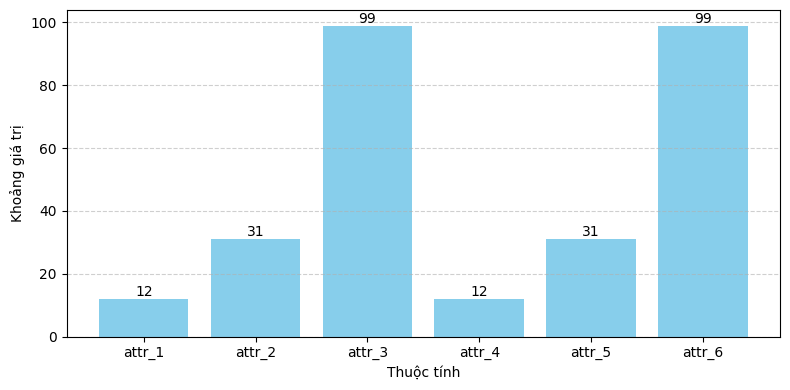

In [18]:
# =========================
# BIỂU ĐỒ CỘT KHOẢNG GIÁ TRỊ CỦA 6 THUỘC TÍNH
# =========================
attrs = [c for c in y_train.columns if c.startswith("attr_")]

y_all = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

attr_range_df = pd.DataFrame({
    "attr": attrs,
    "min_value": [y_all[a].min() for a in attrs],
    "max_value": [y_all[a].max() for a in attrs],
})

attr_range_df["value_range"] = attr_range_df["max_value"] - attr_range_df["min_value"] + attr_range_df["min_value"]

display(attr_range_df)

plt.figure(figsize=(8, 4))
plt.bar(attr_range_df["attr"], attr_range_df["value_range"], color="skyblue")
plt.xlabel("Thuộc tính")
plt.ylabel("Khoảng giá trị")
plt.grid(True, axis="y", linestyle="--", alpha=0.6)

for i, v in enumerate(attr_range_df["value_range"]):
    plt.text(i, v, str(v), ha="center", va="bottom")

plt.tight_layout()
plt.show()

# Kiểm tra leakage

In [19]:
# Kiểm tra ID trùng và thiếu
def audit_split(X, Y, name):
    setX = set(X["id"])
    setY = set(Y["id"])
    missY = setX - setY
    missX = setY - setX
    print(f"\n===== Tập {name} ======")
    print("Tổng ID trong X:", len(setX))
    print("Tổng ID trong Y:", len(setY))
    print("ID có trong X nhưng thiếu trong Y:", len(missY))
    print("ID có trong Y nhưng thiếu trong X:", len(missX))

audit_split(X_train, y_train, "TRAIN")
audit_split(X_val, y_val, "VAL")

print("\n=============================")
print(f"ID trùng giữa TRAIN và VAL:", len(set(X_train["id"]).intersection(set(X_val["id"]))))
print(f"ID trùng giữa TRAIN và TEST:", len(set(X_train["id"]).intersection(set(X_test["id"]))))


===== Tập TRAIN ======
Tổng ID trong X: 51000
Tổng ID trong Y: 51000
ID có trong X nhưng thiếu trong Y: 0
ID có trong Y nhưng thiếu trong X: 0

===== Tập VAL ======
Tổng ID trong X: 7200
Tổng ID trong Y: 7200
ID có trong X nhưng thiếu trong Y: 0
ID có trong Y nhưng thiếu trong X: 0

ID trùng giữa TRAIN và VAL: 0
ID trùng giữa TRAIN và TEST: 0


Nhận xét: Dữ liệu sạch, ID khách hàng trên các tập DL đều không bị trùng 

In [20]:
# Hiển thị khoảng giá trị (min, max, unique) cho từng thuộc tính trong y_train
print(y_train.describe(include='all'))
print(y_train.nunique())

           id        attr_1        attr_2        attr_3        attr_4  \
count   51000  51000.000000  51000.000000  51000.000000  51000.000000   
unique  51000           NaN           NaN           NaN           NaN   
top     f6oqr           NaN           NaN           NaN           NaN   
freq        1           NaN           NaN           NaN           NaN   
mean      NaN      7.822392     12.225529     50.063647      7.865098   
std       NaN      3.980223     10.132358     28.641257      3.975927   
min       NaN      1.000000      1.000000      1.000000      1.000000   
25%       NaN      3.000000      1.000000     25.000000      3.000000   
50%       NaN      9.000000     11.000000     50.000000     11.000000   
75%       NaN     12.000000     21.000000     75.000000     12.000000   
max       NaN     12.000000     31.000000     99.000000     12.000000   

              attr_5        attr_6  
count   51000.000000  51000.000000  
unique           NaN           NaN  
top         

# Phân tích hành vi khách hàng

## Độ dài


======== Phân bố độ dài trên TRAIN =========
Min - Mean - Max: 3 12.81 37
p50 - p90 - p95 - p99: {0.5: 12.0, 0.9: 17.0, 0.95: 19.0, 0.99: 37.0}

======== Phân bố độ dài trên VAL =========
Min - Mean - Max: 3 16.01 37
p50 - p90 - p95 - p99: {0.5: 14.0, 0.9: 24.0, 0.95: 37.0, 0.99: 37.0}


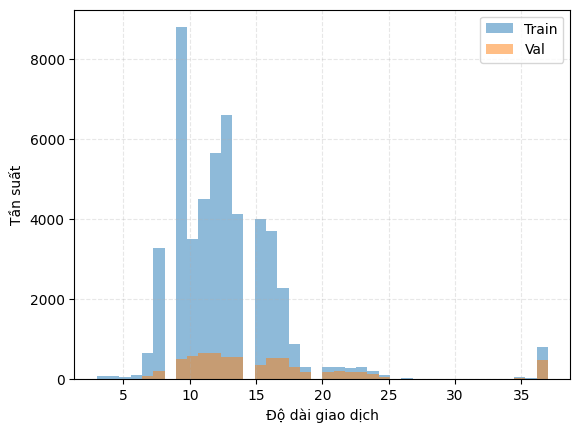

In [44]:
# Chuyển về độ dài hành vi của mỗi KH (số features không NaN)
tr_len = X_train[feat_cols].notna().sum(axis=1)
va_len = X_val[feat_cols].notna().sum(axis=1)

# Thống kê phân phối độ dài hành vi
def summarize_len(s, name):
    q = s.quantile([0.5, 0.9, 0.95, 0.99]).to_dict()
    print(f"\n======== Phân bố độ dài trên {name} =========")
    
    # Thông kê cơ bản
    print("Min - Mean - Max:", int(s.min()), round(float(s.mean()), 2), int(s.max()))
    
    # Percentiles
    print("p50 - p90 - p95 - p99:", {k: float(v) for k,v in q.items()})

summarize_len(tr_len, "TRAIN")
summarize_len(va_len, "VAL")

plt.figure()
plt.hist(tr_len, bins=40, alpha=0.5, label="Train")
plt.hist(va_len, bins=40, alpha=0.5, label="Val")
# plt.title("Phân phối độ dài hành vi")
plt.xlabel("Độ dài giao dịch"); plt.ylabel("Tần suất")
plt.legend()
plt.grid(True, alpha=0.3, linestyle="--")
plt.show()

Nhận xét: 
- Đa số phiên có độ dài quanh khoảng 12 hành vi 
- Độ dài hành vi khá lệch (p99 >>p90), phát hiện một nhóm khách hàng thực hiện khá nhiều thao tác trong vòng 4 tuần (chọn lâu, thay đổi ý định???) trong khi chỉ cần tối thiểu 3 hành vi để 1 đơn hàng được hoàn tất 

## Độ đa dạng và phổ biến 


===== TRAIN =====
Số hành vi khác nhau: 254

Top 5 hành vi phổ biến nhất (chiếm 24.51% trong tổng số hành vi):
  1.105: 56478 (8.64%)
  2.102: 41036 (6.28%)
  3.103: 25704 (3.93%)
  4.760: 18524 (2.84%)
  5.8615: 18396 (2.82%)

Số hành vi hiếm (<p50>): 127 (50.0%)
Top 5 hành vi hiếm nhất:
  1.978: 898 (0.14%)
  2.1984: 889 (0.14%)
  3.1356: 889 (0.14%)
  4.785: 889 (0.14%)
  5.1338: 889 (0.14%)

===== VAL =====
Số hành vi khác nhau: 254

Top 5 hành vi phổ biến nhất (chiếm 20.84% trong tổng số hành vi):
  1.102: 7725 (6.70%)
  2.105: 5784 (5.02%)
  3.103: 5132 (4.45%)
  4.12516: 3023 (2.62%)
  5.760: 2370 (2.06%)

Số hành vi hiếm (<p50>): 126 (49.6%)
Top 5 hành vi hiếm nhất:
  1.884: 134 (0.12%)
  2.881: 132 (0.11%)
  3.871: 131 (0.11%)
  4.849: 130 (0.11%)
  5.1081: 130 (0.11%)


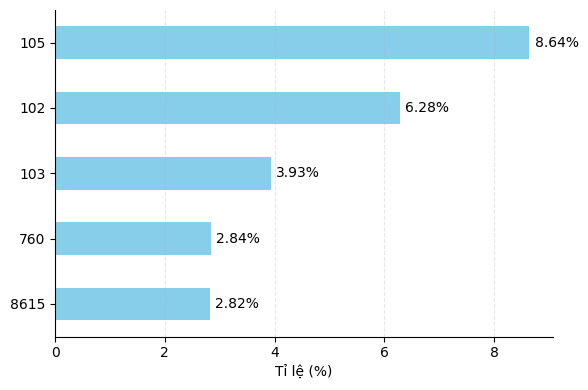

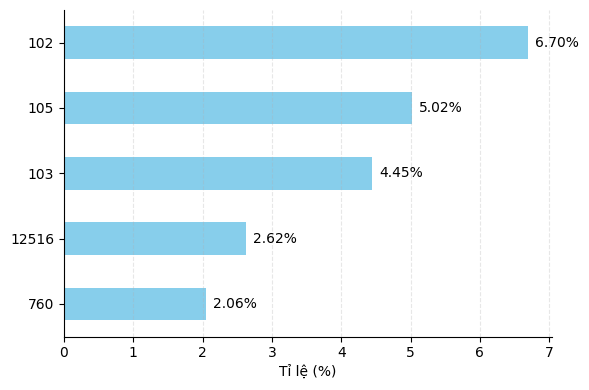

In [49]:
# Hàm phân tích tần suất hành vi
def analyze_event_freq(X, cols, name):
    print(f"\n===== {name} =====")
    # Đếm số lần xuất hiện
    s = X[cols].stack().dropna().astype(int)
    freq = s.value_counts()
    
    print(f"Số hành vi khác nhau: {len(freq)}")
    
    # Top 5 hành vi phổ biến nhất
    cum = (freq.cumsum() / freq.sum()).iloc[4] * 100
    print(f"\nTop 5 hành vi phổ biến nhất", f"(chiếm {cum:.2f}% trong tổng số hành vi):")
    for i, (event, count) in enumerate(freq.head(5).items(), 1):
        pct = count / len(s) * 100
        print(f"  {i}.{event}: {count} ({pct:.2f}%)")

    # Hành vi hiếm
    rare_threshold = freq.quantile(0.5)
    very_rare = (freq < rare_threshold).sum()
    ultra_rare = (freq < 5).sum()
    print(f"\nSố hành vi hiếm (<p50>): {very_rare} ({very_rare/len(freq)*100:.1f}%)")
    print(f"Top 5 hành vi hiếm nhất:")
    for i, (event, count) in enumerate(freq[freq < rare_threshold].head(5).items(), 1):
        pct = count / len(s) * 100
        print(f"  {i}.{event}: {count} ({pct:.2f}%)")
    
    # Vẽ biểu đồ
    vals = (freq / freq.sum() * 100).sort_values(ascending=False).head(5)

    fig, ax = plt.subplots(figsize=(6,4))
    vals.plot(kind='barh', ax=ax, color = 'skyblue')

    # Đảo trục để thanh lớn nhất ở trên
    ax.invert_yaxis()

    # Thêm tỉ lệ lên từng thanh
    for i, v in enumerate(vals):
        ax.text(v + 0.1, i, f"{v:.2f}%", va='center')

    # Xóa viền trên và phải
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.set_xlabel("Tỉ lệ (%)")
    #ax.set_title(f"Top 5 hành vi phổ biến nhất trên tập {name}", fontweight='bold')
    
    ax.grid(True, axis='x', linestyle='--', alpha=0.3)

    plt.tight_layout()
    
    return freq

freq_tr = analyze_event_freq(X_train, feat_cols, "TRAIN")
freq_val = analyze_event_freq(X_val, feat_cols, "VAL")

- Top 5 hành vi phổ biến bao phủ một phần khá lớn trên bộ DL ==> Bag of events baseline mạnh
- Không có event nào quá ít


===== POSITION ANALYSIS - TRAIN =====

Top 5 hành vi đầu tiên
  1. Event 760: 8227 (16.13%)
  2. Event 685: 7919 (15.53%)
  3. Event 836: 4153 (8.14%)
  4. Event 7943: 4116 (8.07%)
  5. Event 10477: 4104 (8.05%)

Top 5 hành vi cuối cùng:
  1. Event 1027: 3546 (6.95%)
  2. Event 995: 3528 (6.92%)
  3. Event 1080: 3496 (6.85%)
  4. Event 975: 3484 (6.83%)
  5. Event 1071: 3453 (6.77%)


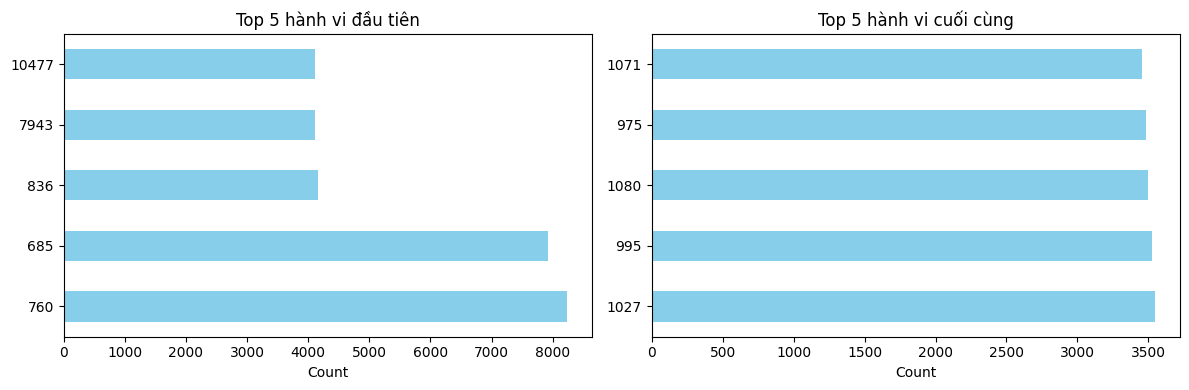


===== POSITION ANALYSIS - VAL =====

Top 5 hành vi đầu tiên
  1. Event 1076: 2158 (29.97%)
  2. Event 131: 566 (7.86%)
  3. Event 760: 556 (7.72%)
  4. Event 12516: 552 (7.67%)
  5. Event 1338: 544 (7.56%)

Top 5 hành vi cuối cùng:
  1. Event 1027: 425 (5.90%)
  2. Event 977: 422 (5.86%)
  3. Event 1104: 407 (5.65%)
  4. Event 1059: 402 (5.58%)
  5. Event 995: 395 (5.49%)


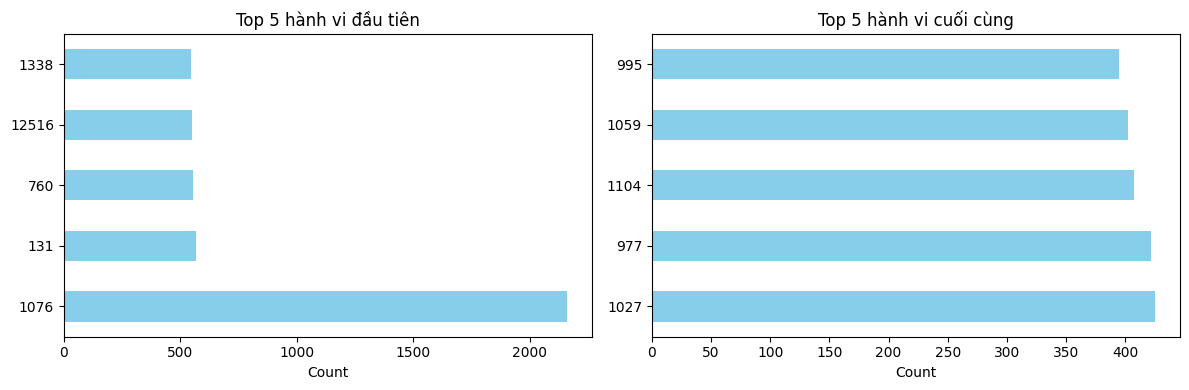

In [23]:
# Hàm phân tích chi tiết các hành vi đầu cuối
def analyze_position_events(X, cols, name):
    first_events = []
    last_events = []
    
    for _, row in X.iterrows():
        seq = row[cols].dropna().astype(int).tolist()
        if len(seq) > 0:
            first_events.append(seq[0])
            last_events.append(seq[-1])
    
    first_freq = pd.Series(first_events).value_counts()
    last_freq = pd.Series(last_events).value_counts()
    
    print(f"\n===== POSITION ANALYSIS - {name} =====")
    print(f"\nTop 5 hành vi đầu tiên")
    for i, (event, count) in enumerate(first_freq.head(5).items(), 1):
        pct = count / len(first_events) * 100
        print(f"  {i}. Event {event}: {count} ({pct:.2f}%)")
    
    print(f"\nTop 5 hành vi cuối cùng:")
    for i, (event, count) in enumerate(last_freq.head(5).items(), 1):
        pct = count / len(last_events) * 100
        print(f"  {i}. Event {event}: {count} ({pct:.2f}%)")
    
    
    # Vẽ biểu đồ
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    first_freq.head(5).plot(kind='barh', ax=axes[0], color='skyblue')
    axes[0].set_xlabel("Count")
    axes[0].set_title("Top 5 hành vi đầu tiên")
    

    last_freq.head(5).plot(kind='barh', ax=axes[1], color='skyblue')
    axes[1].set_xlabel("Count")
    axes[1].set_title("Top 5 hành vi cuối cùng")
    plt.tight_layout()
    plt.show()
    
    return first_freq, last_freq

first_freq_tr, last_freq_tr = analyze_position_events(X_train, feat_cols, "TRAIN")
first_freq_val, last_freq_val = analyze_position_events(X_val, feat_cols, "VAL")



Các hành vi cuối không mang nhiều ý nghĩa cho lắm, hành vi đầu khác nhau ==> Mô hình baseline dễ học sai 

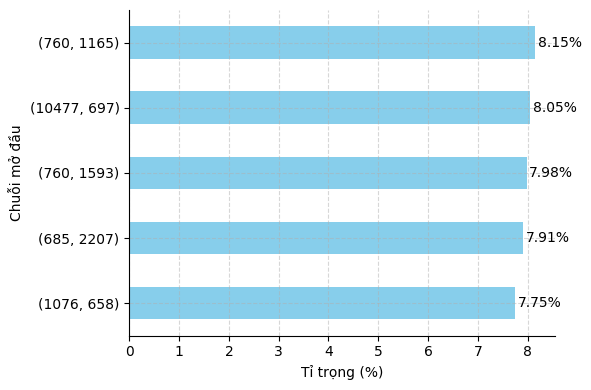

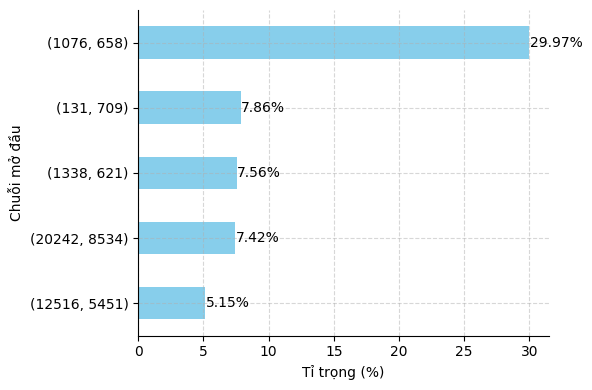

In [47]:
def seq_len(df):
    return df[feat_cols].notna().sum(axis=1)

def prefix_k(df, k=2):
    arr = df[feat_cols].to_numpy()
    lens = seq_len(df).to_numpy()
    out = []
    for i, ln in enumerate(lens):
        ln = int(ln)
        seq = arr[i, :min(k, ln)]
        seq = [int(x) for x in seq if not np.isnan(x)]
        out.append(tuple(seq))
    return pd.Series(out)

def top_prefix(df, name, k=2, top_n=12):
    px = prefix_k(df, k=k).value_counts().head(top_n)
    
    total = len(df)
    res = pd.DataFrame({
        "Số lượng": px,
        "Tỉ trọng (%)": (px / total * 100)
    }).sort_values("Tỉ trọng (%)", ascending=False)


    # vẽ biểu đồ
    fig, ax = plt.subplots(figsize=(6,4))
    vals = res["Tỉ trọng (%)"]

    vals.plot(kind="barh", ax=ax, color="skyblue")

    ax.invert_yaxis()

    # ghi % lên thanh
    for i, v in enumerate(vals):
        ax.text(v + 0.05, i, f"{v:.2f}%", va="center")

    # bỏ viền thừa
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # kẻ caro
    ax.grid(True, axis="both", linestyle="--", alpha=0.5)

    ax.set_xlabel("Tỉ trọng (%)")
    ax.set_ylabel(f"Chuỗi mở đầu")
    #ax.set_title(f"Top {top_n} luồng bắt đâu phổ biến trên {name}")

    plt.tight_layout()

top_prefix(X_train, "TRAIN", k=2, top_n=5)
top_prefix(X_val,  "VALID",  k=2, top_n=5)


- Luồng hành vi ngay từ khi bắt đầu của dữ liệu VALID khác hẳn và chênh lệch nhiều so với TRAIN 

=> Rất nhạy cảm với các mô hình baseline, dễ lệch khi phân phối thay đổi
=> Các mô hình DL học cả chuỗi, không bị hiểu nhầm ngay từ bước đầu 

- Đội ngũ sales: có một luồng đang được tập trung mạnh ở các đơn hàng trên tập dự đoán VALID có thể làm thay đổi cơ cấu nhu cầu & tồn kho




========TRAIN unique_actions=========
Mean: 10.911450980392157 
| p90: 15.0 | p99: 22.0

========TRAIN repeat_ratio=========
Mean: 0.13580723369399872 
| p90: 0.2777777777777778 | p99: 0.4054054054054054


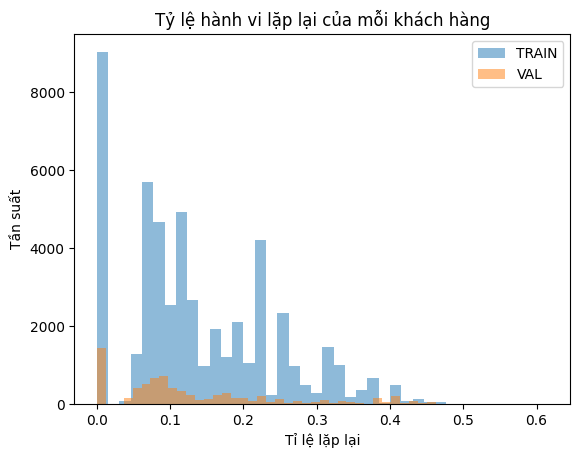

In [25]:
# Hàm tính số action khác nhau trên mỗi hàng
def unique_actions_df(X):
    # Số action khác nhau trên mỗi hàng 
    return X[feat_cols].apply(lambda r: r.dropna().astype(int).nunique(), axis=1).rename("unique_actions")

# Hàm thông kê 
def stats(a, name):
    print(f"\n========{name}=========")
    print("Mean:", float(a.mean()), "\n| p90:", float(a.quantile(0.9)), "| p99:", float(a.quantile(0.99)))
    
tr_unique = unique_actions_df(X_train)
va_unique = unique_actions_df(X_val)

tr_repeat = (1 - tr_unique / tr_len.replace(0, np.nan)).fillna(0).rename("repeat_ratio")
va_repeat = (1 - va_unique / va_len.replace(0, np.nan)).fillna(0).rename("repeat_ratio")

stats(tr_unique, "TRAIN unique_actions")
stats(tr_repeat, "TRAIN repeat_ratio")

plt.figure()
plt.hist(tr_repeat, bins=40, alpha=0.5, label="TRAIN")
plt.hist(va_repeat, bins=40, alpha=0.5, label="VAL")
plt.title("Tỷ lệ hành vi lặp lại của mỗi khách hàng")
plt.xlabel("Tỉ lệ lặp lại"); plt.ylabel("Tần suất")
plt.legend(); plt.show()


========TRAIN unique_actions=========
Mean: 10.911450980392157 
| p90: 15.0 | p99: 22.0

========TRAIN repeat_ratio=========
Mean: 0.13580723369399872 
| p90: 0.2777777777777778 | p99: 0.4054054054054054


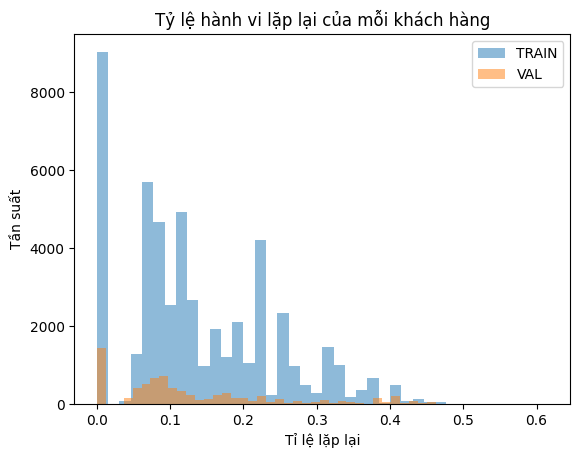

In [26]:
# Hàm tính số action khác nhau trên mỗi hàng
def unique_actions_df(X):
    # Số action khác nhau trên mỗi hàng 
    return X[feat_cols].apply(lambda r: r.dropna().astype(int).nunique(), axis=1).rename("unique_actions")

# Hàm thông kê 
def stats(a, name):
    print(f"\n========{name}=========")
    print("Mean:", float(a.mean()), "\n| p90:", float(a.quantile(0.9)), "| p99:", float(a.quantile(0.99)))
    
tr_unique = unique_actions_df(X_train)
va_unique = unique_actions_df(X_val)

tr_repeat = (1 - tr_unique / tr_len.replace(0, np.nan)).fillna(0).rename("repeat_ratio")
va_repeat = (1 - va_unique / va_len.replace(0, np.nan)).fillna(0).rename("repeat_ratio")

stats(tr_unique, "TRAIN unique_actions")
stats(tr_repeat, "TRAIN repeat_ratio")

plt.figure()
plt.hist(tr_repeat, bins=40, alpha=0.5, label="TRAIN")
plt.hist(va_repeat, bins=40, alpha=0.5, label="VAL")
plt.title("Tỷ lệ hành vi lặp lại của mỗi khách hàng")
plt.xlabel("Tỉ lệ lặp lại"); plt.ylabel("Tần suất")
plt.legend(); plt.show()

## Rollback
Hệ thống mua sắm có đang thực sự tốt không?

In [27]:
from collections import Counter, defaultdict

In [28]:
# Hàm đếm số lần xuất hiện rollback A-B-A trong một hàng
def count_rollback(row):
    # Lấy các cột có hành vi 
    s = row[feat_cols].dropna().astype(int).tolist()
    if len(s) < 3: 
        return 0  # Độ dài < 3 thì không thể có rollback
    return sum(1 for i in range(len(s)-2) if s[i] == s[i+2] and s[i] != s[i+1])

# Tạo thêm cột rollback
X_train['rollback_aba'] = X_train.apply(count_rollback, axis=1)
X_val['rollback_aba'] = X_val.apply(count_rollback, axis=1)

Thống kê rollback trên tập TRAIN:
count    51000.000000
mean         0.394471
std          0.805553
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          4.000000
Name: rollback_aba, dtype: float64

Thống kê rollback trên tập VAL:
count    7200.000000
mean        0.225972
std         0.640286
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         4.000000
Name: rollback_aba, dtype: float64
Số rollback > 2 trên tập TRAIN: 298 (0.58%)
Số rollback > 2 trên tập VAL: 23 (0.32%)


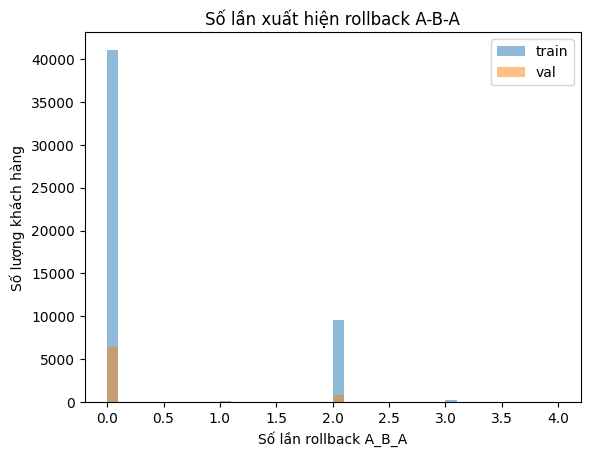

In [29]:
print("Thống kê rollback trên tập TRAIN:")
print(X_train["rollback_aba"].describe())
print("\nThống kê rollback trên tập VAL:")
print(X_val["rollback_aba"].describe())

print(f"Số rollback > 2 trên tập TRAIN: {(X_train['rollback_aba'] > 2).sum()} ({(X_train['rollback_aba'] > 2).sum() / len(X_train) * 100:.2f}%)")
print(f"Số rollback > 2 trên tập VAL: {(X_val['rollback_aba'] > 2).sum()} ({(X_val['rollback_aba'] > 2).sum() / len(X_val) * 100:.2f}%)")

plt.figure()
plt.hist(X_train['rollback_aba'], bins=40, alpha=0.5, label="train")
plt.hist(X_val['rollback_aba'], bins=40, alpha=0.5, label="val")
plt.title("Số lần xuất hiện rollback A-B-A")
plt.xlabel("Số lần rollback A_B_A"); plt.ylabel("Số lượng khách hàng")
plt.legend(); plt.show()

Rollback tồn tại nhưng khá hợp lý với sô lần tối đa chỉ là 4 và chiếm khá ít, số rollback 2 lần chiếm lượng lớn do gặp lỗi kĩ thuật ng dùng thường có xu hướng thử lại đúng 2 lần trước khi bỏ cuộc thay vì 1 :'> 

==> Không cần tập trung vào phần này

In [30]:
# Liệt kê các cặp rollback phổ biến 
rollback_patterns = []
for _, row in X_train.iterrows():    
    # Lấy chuỗi hành động
    s = row[feat_cols].dropna().astype(int).tolist()
    
    # Tìm mẫu A-B-A
    for i in range(len(s) - 2):
        if s[i] == s[i+2] and s[i] != s[i+1]:
            # Lưu cặp (A, B), nghĩa là từ A sang B rồi quay lại A
            rollback_patterns.append((s[i], s[i+1]))

# Đếm tần suất các cặp rollback
pattern_counts = Counter(rollback_patterns)

print(f"{len(rollback_patterns)} mẫu A-B-A trên tập TRAIN")
print()
print(f"{'Hành động A':<15} | {'Hành động B':<15} | {'Số lần lặp lại'}")
print()

# In ra top 50 cặp phổ biến nhất
for (a, b), count in pattern_counts.most_common(50):
    print(f"{a:<15} | {b:<15} | {count} lần")

20118 mẫu A-B-A trên tập TRAIN

Hành động A     | Hành động B     | Số lần lặp lại

105             | 906             | 686 lần
105             | 1243            | 665 lần
105             | 1042            | 664 lần
105             | 907             | 663 lần
105             | 1127            | 658 lần
105             | 1455            | 657 lần
105             | 976             | 654 lần
105             | 992             | 653 lần
105             | 979             | 650 lần
105             | 1265            | 645 lần
105             | 989             | 645 lần
105             | 1012            | 643 lần
105             | 1195            | 642 lần
105             | 867             | 637 lần
105             | 1159            | 636 lần
105             | 905             | 634 lần
105             | 775             | 629 lần
105             | 1126            | 622 lần
105             | 1244            | 617 lần
105             | 929             | 613 lần
105             | 1072            | 

Số lần lặp lại của các thao tác khác từ 105 khá lớn, hành vi 105 có thể là trung tâm trong hệ thống để dẫn đến các hành vi khác (trạng thái gốc/màn hình gốc/ bước xác nhận)


In [31]:
# Tỷ lệ % xuất hiện hành động 105 trên tổng số hành vi
print("Tỷ lệ % xuất hiện hành động 105 trên TRAIN:", (X_train[feat_cols] == 105).sum().sum() / X_train[feat_cols].count().sum() * 100)
print("Tỷ lệ % xuất hiện hành động 105 trên VALID:", (X_val[feat_cols] == 105).sum().sum() / X_val[feat_cols].count().sum() * 100)
print("Tỷ lệ % xuất hiện hành động 105 trên TEST:", (X_test[feat_cols] == 105).sum().sum() / X_test[feat_cols].count().sum() * 100)

Tỷ lệ % xuất hiện hành động 105 trên TRAIN: 8.644000869328321
Tỷ lệ % xuất hiện hành động 105 trên VALID: 5.016174213187404
Tỷ lệ % xuất hiện hành động 105 trên TEST: 3.841661088580016


Cao quá :< 

In [32]:
# Chuyển mỗi dòng thành 1 chuỗi event (bỏ NaN padding)
def build_sequences_with_id(X, cols):
    arr = X[cols].to_numpy()
    ids = X["id"].tolist() if "id" in X.columns else list(range(len(X)))

    seqs = []
    for idx, row in zip(ids, arr):
        seq = row[~pd.isna(row)].astype(int).tolist()
        seqs.append((idx, seq))
    return seqs


def analyze_repeat_and_rollback(X, cols, name="TRAIN", top_n=15):
    seqs = build_sequences_with_id(X, cols)

    n = len(seqs)

    # Tỷ lệ cấp chuỗi
    has_repeat_ge2 = 0
    has_repeat_ge3 = 0
    has_adj_repeat = 0       # A-A
    has_aba = 0              # A-B-A
    has_abab = 0             # A-B-A-B
    has_multi_repeated_tokens = 0  # có từ 2 token khác nhau bị lặp
    has_deep_revisit = 0     # quay lại sau >= 3 bước trung gian

    revisit_rate_list = []
    max_gap_list = []

    # Counter để xem token/pattern nào lặp nhiều
    repeated_token_counter = Counter()  # token xuất hiện >=2 trong một chuỗi
    aba_counter = Counter()
    abab_counter = Counter()
    aba_anchor_counter = Counter()   # token A trong A-B-A
    aba_middle_counter = Counter()   # token B trong A-B-A

    rows = []

    for seq_id, seq in seqs:
        L = len(seq)
        c = Counter(seq)

        # Token lặp
        repeated_tokens = [t for t, v in c.items() if v >= 2]
        if len(repeated_tokens) > 0:
            has_repeat_ge2 += 1
            for t in repeated_tokens:
                repeated_token_counter[t] += 1

        if any(v >= 3 for v in c.values()):
            has_repeat_ge3 += 1

        if len(repeated_tokens) >= 2:
            has_multi_repeated_tokens += 1

        # Tỷ lệ revisit = số lần quay lại / độ dài chuỗi
        revisits = sum(v - 1 for v in c.values() if v >= 2)
        revisit_rate = revisits / L
        revisit_rate_list.append(revisit_rate)

        # A-A
        has_adj = False
        for a, b in zip(seq[:-1], seq[1:]):
            if a == b:
                has_adj = True
                break
        if has_adj:
            has_adj_repeat += 1

        # Gap quay lại sâu nhất
        pos = defaultdict(list)
        for i, t in enumerate(seq):
            pos[t].append(i)

        max_gap = 0
        deep = False
        for t, inds in pos.items():
            for i1, i2 in zip(inds[:-1], inds[1:]):
                gap = i2 - i1 - 1
                max_gap = max(max_gap, gap)
                if gap >= 3:
                    deep = True

        max_gap_list.append(max_gap)
        if deep:
            has_deep_revisit += 1

        # A-B-A và A-B-A-B
        num_aba = 0
        num_abab = 0

        for i in range(L - 2):
            a, b, c1 = seq[i:i+3]
            if a == c1 and a != b:
                num_aba += 1
                aba_counter[(a, b, c1)] += 1
                aba_anchor_counter[a] += 1
                aba_middle_counter[b] += 1

        for i in range(L - 3):
            a, b, c1, d = seq[i:i+4]
            if a == c1 and b == d and a != b:
                num_abab += 1
                abab_counter[(a, b, c1, d)] += 1

        if num_aba > 0:
            has_aba += 1
        if num_abab > 0:
            has_abab += 1

        rows.append({
            "id": seq_id,
            "seq_len": L,
            "num_unique": len(c),
            "num_revisits": revisits,
            "revisit_rate": revisit_rate,
            "num_repeated_tokens": len(repeated_tokens),
            "max_repeat": max(c.values()),
            "has_adj_repeat": int(has_adj),
            "num_aba": num_aba,
            "num_abab": num_abab,
            "max_revisit_gap": max_gap,
            "has_deep_revisit": int(deep),
            "seq_preview": " -> ".join(map(str, seq[:20])) + (" ..." if len(seq) > 20 else "")
        })

    stat_df = pd.DataFrame(rows)

    summary = pd.DataFrame({
        "Chỉ số": [
            "Lặp >= 3",
            "A-A",
            "A-B-A",
            "A-B-A-B",
            "Nhiều hành vi lặp",
            "Quay lại sâu",
        ],
        "Giá trị": [
            has_repeat_ge3 / n,
            has_adj_repeat / n,
            has_aba / n,
            has_abab / n,
            has_multi_repeated_tokens / n,
            has_deep_revisit / n,
        ]
    })

    print(f"\n===== ROLLBACK / REPEAT ANALYSIS - {name} =====")
    display(summary.style.format({"Giá trị": "{:.2%}"}))

    # Biểu đồ tóm tắt
    plot_df = summary.iloc[:7].copy()
    plt.figure(figsize=(9, 5))
    plt.barh(plot_df["Chỉ số"][::-1], plot_df["Giá trị"][::-1] * 100)
    plt.xlabel("% số chuỗi")
    plt.title(f"Tỷ trọng các luồng phức tạp trên tập {name}")
    plt.tight_layout()
    plt.show()

    # Top token bị lặp
    top_repeat_token = pd.DataFrame(
        repeated_token_counter.most_common(top_n),
        columns=["token", "số_chuỗi_có_token_lặp"]
    )

    print(f"\nTop {top_n} token thường bị lặp lại trong cùng 1 chuỗi:")
    display(top_repeat_token)

    # Top A-B-A
    top_aba = pd.DataFrame(
        [(k[0], k[1], k[2], v) for k, v in aba_counter.most_common(top_n)],
        columns=["A", "B", "A_lặp_lại", "count"]
    )

    print(f"\nTop {top_n} mẫu A-B-A:")
    display(top_aba)

    # Top A-B-A-B
    top_abab = pd.DataFrame(
        [(k[0], k[1], k[2], k[3], v) for k, v in abab_counter.most_common(top_n)],
        columns=["A", "B", "A_lặp_lại", "B_lặp_lại", "count"]
    )

    print(f"\nTop {top_n} mẫu A-B-A-B:")
    display(top_abab)

    # Token đóng vai trò "điểm quay lại"
    top_anchor = pd.DataFrame(
        aba_anchor_counter.most_common(top_n),
        columns=["token_anchor_A", "count"]
    )

    print(f"\nTop {top_n} token đóng vai trò điểm quay lại trong A-B-A:")
    display(top_anchor)

    return stat_df, summary, top_repeat_token, top_aba, top_abab, top_anchor


===== ROLLBACK / REPEAT ANALYSIS - TRAIN =====


,Chỉ số,Giá trị
0,Lặp >= 3,21.56%
1,A-A,0.91%
2,A-B-A,19.55%
3,A-B-A-B,0.58%
4,Nhiều hành vi lặp,33.14%
5,Quay lại sâu,81.67%


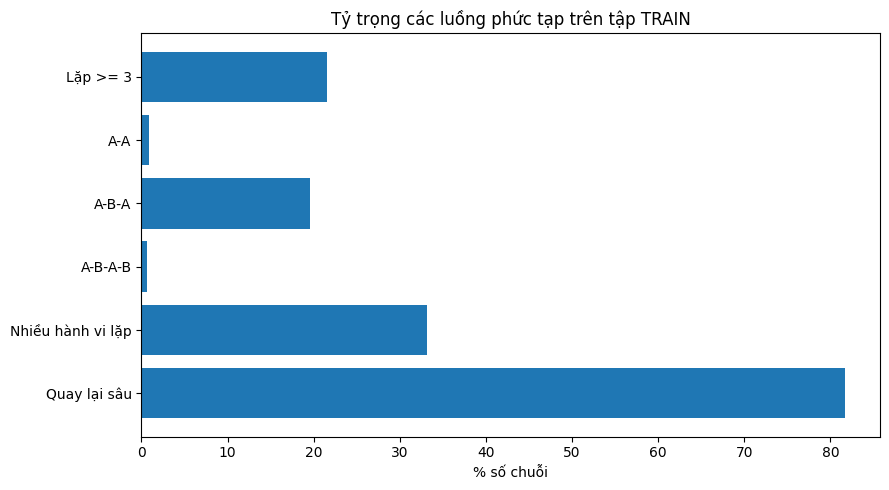


Top 15 token thường bị lặp lại trong cùng 1 chuỗi:


,token,số_chuỗi_có_token_lặp
0,105,18392
1,102,18189
2,760,2715
3,8615,2642
4,685,2390
5,697,1821
6,103,1728
7,929,1562
8,867,1553
9,606,923



Top 15 mẫu A-B-A:


,A,B,A_lặp_lại,count
0,105,906,105,686
1,105,1243,105,665
2,105,1042,105,664
3,105,907,105,663
4,105,1127,105,658
5,105,1455,105,657
6,105,976,105,654
7,105,992,105,653
8,105,979,105,650
9,105,1265,105,645



Top 15 mẫu A-B-A-B:


,A,B,A_lặp_lại,B_lặp_lại,count
0,867,105,867,105,89
1,929,105,929,105,88
2,109,105,109,105,29
3,4347,105,4347,105,18
4,105,1159,105,1159,8
5,4491,105,4491,105,7
6,111,105,111,105,6
7,105,906,105,906,5
8,105,979,105,979,4
9,105,1012,105,1012,4



Top 15 token đóng vai trò điểm quay lại trong A-B-A:


,token_anchor_A,count
0,105,19694
1,929,126
2,867,119
3,109,35
4,4347,22
5,4491,18
6,1159,9
7,1265,9
8,1042,8
9,111,8



===== ROLLBACK / REPEAT ANALYSIS - VALID =====


,Chỉ số,Giá trị
0,Lặp >= 3,18.78%
1,A-A,0.56%
2,A-B-A,11.19%
3,A-B-A-B,0.32%
4,Nhiều hành vi lặp,35.35%
5,Quay lại sâu,79.50%


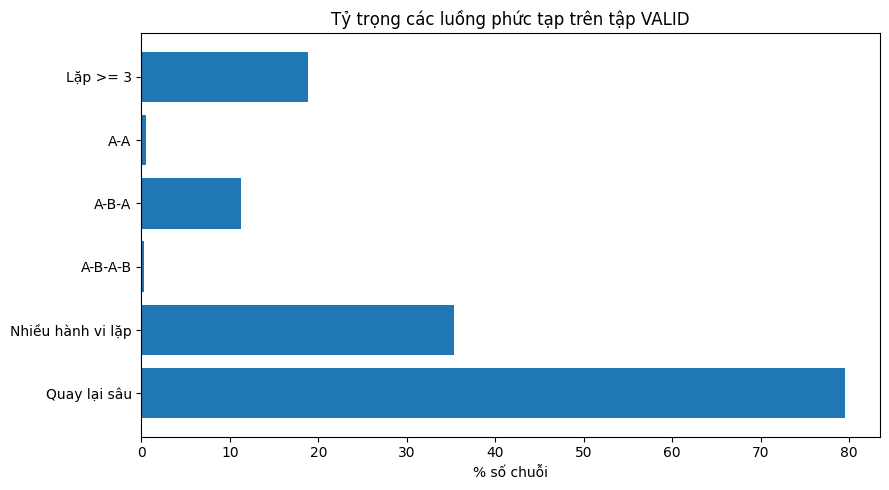


Top 15 token thường bị lặp lại trong cùng 1 chuỗi:


,token,số_chuỗi_có_token_lặp
0,102,3089
1,105,2095
2,103,1078
3,606,555
4,12516,540
5,760,336
6,164,332
7,8615,317
8,5451,308
9,697,162



Top 15 mẫu A-B-A:


,A,B,A_lặp_lại,count
0,105,989,105,65
1,105,1042,105,62
2,105,1159,105,61
3,105,1455,105,59
4,105,1265,105,57
5,105,867,105,57
6,105,1353,105,56
7,105,979,105,55
8,105,1072,105,54
9,105,1243,105,53



Top 15 mẫu A-B-A-B:


,A,B,A_lặp_lại,B_lặp_lại,count
0,867,105,867,105,4
1,929,105,929,105,2
2,105,1353,105,1353,2
3,105,1243,105,1243,2
4,4491,105,4491,105,1
5,4347,105,4347,105,1
6,111,105,111,105,1
7,105,4347,105,4347,1
8,109,105,109,105,1
9,105,1012,105,1012,1



Top 15 token đóng vai trò điểm quay lại trong A-B-A:


,token_anchor_A,count
0,105,1594
1,929,5
2,867,4
3,1353,4
4,1243,3
5,4491,2
6,4347,2
7,111,1
8,109,1
9,1012,1


In [33]:
rollback_train, summary_train, top_repeat_train, top_aba_train, top_abab_train, top_anchor_train = analyze_repeat_and_rollback(
    X_train, feat_cols, name="TRAIN", top_n=15
)

rollback_val, summary_val, top_repeat_val, top_aba_val, top_abab_val, top_anchor_val = analyze_repeat_and_rollback(
    X_val, feat_cols, name="VALID", top_n=15
)

- Rollback >= 2 xuất hiệu phổ biến --> Không phải bất thường 
- Chuỗi có dấu hiệu quay lại phức tạp cần thỏa mãn 1 trong các điều kiện sau: 
    + Có ít nhất 1 mẫu A-B-A-B
    + Có >= 3 mẫu A-B-A
    + Có >= 3 token khác nhau bị lặp và quay lại sau >=4 hành vi 

In [34]:
def detect_complex_rollback_candidates(stat_df, name="TRAIN", top_n=30):
    # Heuristic: không khẳng định rollback thật
    cand = stat_df[
        (stat_df["num_abab"] >= 1) |
        (stat_df["num_aba"] >= 3) |
        (
            (stat_df["num_repeated_tokens"] >= 3) &
            (stat_df["max_revisit_gap"] >= 4)
        )
    ].copy()

    cand = cand.sort_values(
        ["num_abab", "num_aba", "num_repeated_tokens", "max_revisit_gap", "revisit_rate"],
        ascending=[False, False, False, False, False]
    ).reset_index(drop=True)

    print(f"\n===== COMPLEX ROLLBACK-LIKE CANDIDATES - {name} =====")
    print(f"Số chuỗi candidate: {len(cand):,} / {len(stat_df):,} ({len(cand)/len(stat_df):.2%})")

    display(
        cand.head(top_n)[[
            "id", "seq_len", "num_revisits", "revisit_rate",
            "num_repeated_tokens", "max_repeat",
            "num_aba", "num_abab", "max_revisit_gap",
            "seq_preview"
        ]].style.format({
            "revisit_rate": "{:.2%}"
        })
    )

    return cand

In [35]:
complex_rb_train = detect_complex_rollback_candidates(rollback_train, name="TRAIN", top_n=30)
complex_rb_val = detect_complex_rollback_candidates(rollback_val, name="VALID", top_n=30)


===== COMPLEX ROLLBACK-LIKE CANDIDATES - TRAIN =====
Số chuỗi candidate: 6,043 / 51,000 (11.85%)


,id,seq_len,num_revisits,revisit_rate,num_repeated_tokens,max_repeat,num_aba,num_abab,max_revisit_gap,seq_preview
0,b9e69,13,8,61.54%,4,4,4,2,6,109 -> 105 -> 109 -> 105 -> 15881 -> 995 -> 735 -> 109 -> 105 -> 109 -> 105 -> 15881 -> 995
1,h6xzo,17,5,29.41%,3,4,4,2,5,1076 -> 658 -> 3316 -> 760 -> 1165 -> 105 -> 4275 -> 105 -> 4275 -> 822 -> 10686 -> 10909 -> 704 -> 105 -> 1012 -> 105 -> 1012
2,y9ykd,13,5,38.46%,3,4,4,2,4,867 -> 105 -> 867 -> 105 -> 15342 -> 1027 -> 103 -> 4347 -> 105 -> 4347 -> 105 -> 20022 -> 1080
3,i5bfg,13,6,46.15%,2,4,4,2,4,929 -> 105 -> 929 -> 105 -> 21040 -> 1080 -> 735 -> 929 -> 105 -> 929 -> 105 -> 20022 -> 1059
4,z946c,15,7,46.67%,5,4,3,1,7,685 -> 2207 -> 8615 -> 105 -> 906 -> 105 -> 3562 -> 694 -> 685 -> 2207 -> 8615 -> 105 -> 1159 -> 105 -> 1159
5,uzu4o,15,7,46.67%,5,4,3,1,7,760 -> 1593 -> 8615 -> 105 -> 1265 -> 105 -> 1265 -> 694 -> 760 -> 1593 -> 8615 -> 105 -> 107 -> 105 -> 3114
6,rxxiu,15,7,46.67%,5,4,3,1,7,760 -> 1593 -> 8615 -> 105 -> 929 -> 105 -> 4306 -> 694 -> 760 -> 1593 -> 8615 -> 105 -> 775 -> 105 -> 775
7,ugpcv,13,6,46.15%,4,4,3,1,6,111 -> 105 -> 4507 -> 105 -> 21355 -> 1080 -> 103 -> 929 -> 105 -> 929 -> 105 -> 21355 -> 1080
8,f8xia,13,6,46.15%,4,4,3,1,6,685 -> 1464 -> 105 -> 989 -> 105 -> 1265 -> 694 -> 685 -> 1464 -> 105 -> 1159 -> 105 -> 1159
9,dk6gb,13,6,46.15%,4,4,3,1,6,685 -> 1464 -> 105 -> 4347 -> 105 -> 2032 -> 694 -> 685 -> 1464 -> 105 -> 4275 -> 105 -> 4275



===== COMPLEX ROLLBACK-LIKE CANDIDATES - VALID =====
Số chuỗi candidate: 1,232 / 7,200 (17.11%)


,id,seq_len,num_revisits,revisit_rate,num_repeated_tokens,max_repeat,num_aba,num_abab,max_revisit_gap,seq_preview
0,y5sp6,16,5,31.25%,3,4,4,2,4,1076 -> 658 -> 3316 -> 12516 -> 5451 -> 105 -> 1353 -> 105 -> 1353 -> 822 -> 164 -> 889 -> 105 -> 1243 -> 105 -> 1243
1,whff9,18,7,38.89%,5,4,3,1,7,1076 -> 658 -> 3316 -> 685 -> 2207 -> 8615 -> 105 -> 929 -> 105 -> 929 -> 822 -> 685 -> 2207 -> 8615 -> 105 -> 905 -> 105 -> 4539
2,fy4am,14,5,35.71%,3,4,3,1,5,1076 -> 658 -> 3316 -> 836 -> 105 -> 1012 -> 105 -> 1012 -> 822 -> 836 -> 105 -> 1455 -> 105 -> 992
3,tsw4e,11,5,45.45%,2,4,3,1,5,109 -> 105 -> 1127 -> 105 -> 1117 -> 735 -> 109 -> 105 -> 109 -> 105 -> 871
4,hpzw3,12,5,41.67%,2,4,3,1,5,867 -> 105 -> 1455 -> 105 -> 10795 -> 103 -> 867 -> 105 -> 867 -> 105 -> 17980 -> 1027
5,j7slt,17,4,23.53%,2,4,3,1,5,1076 -> 658 -> 3316 -> 10477 -> 697 -> 105 -> 1244 -> 105 -> 992 -> 822 -> 760 -> 1593 -> 8615 -> 105 -> 1353 -> 105 -> 1353
6,ijeh2,18,4,22.22%,2,4,3,1,5,1076 -> 658 -> 3316 -> 164 -> 17762 -> 2613 -> 105 -> 989 -> 105 -> 989 -> 822 -> 760 -> 1593 -> 8615 -> 105 -> 1244 -> 105 -> 976
7,kgo2g,18,4,22.22%,2,4,3,1,5,1076 -> 658 -> 3316 -> 760 -> 1593 -> 8615 -> 105 -> 929 -> 105 -> 2602 -> 822 -> 164 -> 17762 -> 2613 -> 105 -> 1195 -> 105 -> 1195
8,l6vbx,19,4,21.05%,2,4,3,1,5,1076 -> 658 -> 3316 -> 12516 -> 5451 -> 4521 -> 2669 -> 105 -> 1126 -> 105 -> 1126 -> 822 -> 10686 -> 10909 -> 704 -> 105 -> 1042 -> 105 -> 4391
9,gzikx,12,4,33.33%,2,4,3,1,4,867 -> 105 -> 1265 -> 105 -> 15342 -> 975 -> 735 -> 4491 -> 105 -> 4491 -> 105 -> 1004


In [36]:
def compare_repeat_summary(summary_train, summary_val):
    tr = summary_train.copy().rename(columns={"Giá trị": "TRAIN"})
    va = summary_val.copy().rename(columns={"Giá trị": "VALID"})

    cmp = tr.merge(va, on="Chỉ số", how="inner")
    cmp["VALID - TRAIN"] = cmp["VALID"] - cmp["TRAIN"]

    print("\n===== SO SÁNH TRAIN vs VALID =====")
    display(
        cmp.style.format({
            "TRAIN": "{:.2%}",
            "VALID": "{:.2%}",
            "VALID - TRAIN": "{:+.2%}"
        })
    )

    return cmp

compare_repeat_summary(summary_train, summary_val)


===== SO SÁNH TRAIN vs VALID =====


,Chỉ số,TRAIN,VALID,VALID - TRAIN
0,Lặp >= 3,21.56%,18.78%,-2.79%
1,A-A,0.91%,0.56%,-0.36%
2,A-B-A,19.55%,11.19%,-8.35%
3,A-B-A-B,0.58%,0.32%,-0.26%
4,Nhiều hành vi lặp,33.14%,35.35%,+2.21%
5,Quay lại sâu,81.67%,79.50%,-2.17%


,Chỉ số,TRAIN,VALID,VALID - TRAIN
0,Lặp >= 3,0.215647,0.187778,-0.027869
1,A-A,0.009137,0.005556,-0.003582
2,A-B-A,0.195451,0.111944,-0.083507
3,A-B-A-B,0.005843,0.003194,-0.002649
4,Nhiều hành vi lặp,0.331373,0.353472,0.022100
5,Quay lại sâu,0.816725,0.795000,-0.021725


## Bigram

In [37]:
from IPython.display import display

# Hàm chuyển mỗi dòng thành 1 chuỗi hành vi (bỏ NaN padding)
def build_sequences(X, cols):
    arr = X[cols].to_numpy()
    seqs = []
    for row in arr:
        seq = row[~pd.isna(row)].astype(int).tolist()
        seqs.append(seq)
    return seqs


# Hàm phân tích bigram (event_t, event_t+1)
def analyze_bigrams(X, cols, name="TRAIN", top_n=15):
    seqs = build_sequences(X, cols)

    bigram_counter = Counter()
    prev_counter = Counter()
    next_counter = Counter()

    for seq in seqs:
        for a, b in zip(seq[:-1], seq[1:]):
            bigram_counter[(a, b)] += 1
            prev_counter[a] += 1
            next_counter[b] += 1

    bg = pd.DataFrame(
        [{"prev": a, "next": b, "count": c} for (a, b), c in bigram_counter.items()]
    ).sort_values("count", ascending=False).reset_index(drop=True)

    bg["share"] = bg["count"] / bg["count"].sum()
    bg["p_next_given_prev"] = bg["count"] / bg["prev"].map(prev_counter)
    bg["p_prev_given_next"] = bg["count"] / bg["next"].map(next_counter)

    total = int(bg["count"].sum())
    unique = int(len(bg))
    top10_cov = float(bg["count"].head(10).sum() / total)
    top100_cov = float(bg["count"].head(100).sum() / total)
    singleton_ratio = float((bg["count"] == 1).mean())
    le5_ratio = float((bg["count"] <= 5).mean())

    print(f"\n===== BIGRAM ANALYSIS - {name} =====")
    print(f"Tổng số bigram: {total:,}")
    print(f"Số bigram khác nhau: {unique:,}")
    print(f"Top 10 bigram bao phủ: {top10_cov:.2%}")
    print(f"Top 100 bigram bao phủ: {top100_cov:.2%}")
    print(f"Tỷ lệ bigram chỉ xuất hiện 1 lần: {singleton_ratio:.2%}")
    print(f"Tỷ lệ bigram xuất hiện <= 5 lần: {le5_ratio:.2%}")

    top_bg = bg.head(top_n).copy()
    top_bg["pair"] = top_bg["prev"].astype(str) + " -> " + top_bg["next"].astype(str)

    plt.figure(figsize=(10, 5))
    plt.barh(top_bg["pair"][::-1], top_bg["share"][::-1] * 100)
    plt.xlabel("% trên tổng số bigram")
    plt.title(f"Top {top_n} bigram phổ biến nhất - {name}")
    plt.tight_layout()
    plt.show()

    display(
        top_bg[["prev", "next", "count", "share", "p_next_given_prev"]]
        .style.format({
            "share": "{:.2%}",
            "p_next_given_prev": "{:.2%}"
        })
    )

    return bg


# Hàm phân tích cụm trạng thái
def analyze_transition_structure(bg, name="TRAIN", min_support=50, top_n=15):
    deterministic = bg[
        (bg["p_next_given_prev"] >= 1.0 - 1e-12) &
        (bg["count"] >= min_support)
    ].copy().sort_values(["count", "prev"], ascending=[False, True]).reset_index(drop=True)

    out_degree = bg.groupby("prev")["next"].nunique().rename("out_degree")
    prev_total = bg.groupby("prev")["count"].sum().rename("total_from_prev")
    top1_share = bg.groupby("prev")["p_next_given_prev"].max().rename("top1_next_share")

    branching = pd.concat([out_degree, prev_total, top1_share], axis=1).reset_index()
    branching = branching.sort_values(
        ["out_degree", "total_from_prev"],
        ascending=[False, False]
    ).reset_index(drop=True)

    print(f"\n===== TRANSITION STRUCTURE - {name} =====")
    print(f"Số cạnh gần như cố định (P(next|prev)=100%, support>={min_support}): {len(deterministic)}")

    if len(deterministic) > 0:
        print("\nTop cạnh gần như cố định:")
        display(
            deterministic.head(top_n)[["prev", "next", "count", "share", "p_next_given_prev"]]
            .style.format({
                "share": "{:.2%}",
                "p_next_given_prev": "{:.2%}"
            })
        )

    print("\nTop event có nhiều nhánh đi tiếp nhất:")
    display(
        branching.head(top_n)
        .style.format({
            "top1_next_share": "{:.2%}"
        })
    )

    tmp = branching.head(top_n).sort_values("out_degree")
    plt.figure(figsize=(8, 5))
    plt.barh(tmp["prev"].astype(str), tmp["out_degree"])
    plt.xlabel("Số event có thể đi tiếp")
    plt.title(f"Top {top_n} event rẽ nhánh mạnh nhất - {name}")
    plt.tight_layout()
    plt.show()

    return deterministic, branching


# Hàm gom cụm luồng đơn giản bằng prefix-k
def analyze_prefix_flow(X, cols, name="TRAIN", k=3, top_n=12):
    seqs = build_sequences(X, cols)

    prefix_counter = Counter()
    for seq in seqs:
        prefix = tuple(seq[:k])
        prefix_counter[prefix] += 1

    prefix_df = pd.DataFrame({
        "prefix": list(prefix_counter.keys()),
        "count": list(prefix_counter.values())
    }).sort_values("count", ascending=False).reset_index(drop=True)

    prefix_df["share"] = prefix_df["count"] / len(seqs)
    prefix_df["prefix_str"] = prefix_df["prefix"].apply(lambda x: " -> ".join(map(str, x)))

    print(f"\n===== PREFIX-{k} FLOW - {name} =====")
    print(f"Số prefix-{k} khác nhau: {len(prefix_df):,}")
    print(f"Top 10 prefix-{k} bao phủ: {prefix_df['count'].head(10).sum() / len(seqs):.2%}")

    plt.figure(figsize=(10, 5))
    tmp = prefix_df.head(top_n).sort_values("count")
    plt.barh(tmp["prefix_str"], tmp["share"] * 100)
    plt.xlabel("% trên tổng số phiên")
    plt.title(f"Top {top_n} prefix-{k} phổ biến nhất - {name}")
    plt.tight_layout()
    plt.show()

    display(
        prefix_df.head(top_n)[["prefix_str", "count", "share"]]
        .style.format({"share": "{:.2%}"})
    )

    return prefix_df


# Hàm so sánh drift bigram giữa TRAIN và VALID
def compare_bigram_drift(bg_train, bg_val, top_n=15):
    tr = bg_train[["prev", "next", "share"]].rename(columns={"share": "share_train"})
    va = bg_val[["prev", "next", "share"]].rename(columns={"share": "share_val"})

    drift = tr.merge(va, on=["prev", "next"], how="outer").fillna(0)
    drift["abs_diff"] = (drift["share_train"] - drift["share_val"]).abs()
    drift["pair"] = drift["prev"].astype(int).astype(str) + " -> " + drift["next"].astype(int).astype(str)
    drift = drift.sort_values("abs_diff", ascending=False).reset_index(drop=True)

    print("\n===== BIGRAM DRIFT: TRAIN vs VALID =====")
    display(
        drift.head(top_n)[["pair", "share_train", "share_val", "abs_diff"]]
        .style.format({
            "share_train": "{:.2%}",
            "share_val": "{:.2%}",
            "abs_diff": "{:.2%}"
        })
    )

    return drift


===== BIGRAM ANALYSIS - TRAIN =====
Tổng số bigram: 602,378
Số bigram khác nhau: 6,710
Top 10 bigram bao phủ: 12.89%
Top 100 bigram bao phủ: 42.81%
Tỷ lệ bigram chỉ xuất hiện 1 lần: 26.62%
Tỷ lệ bigram xuất hiện <= 5 lần: 55.32%


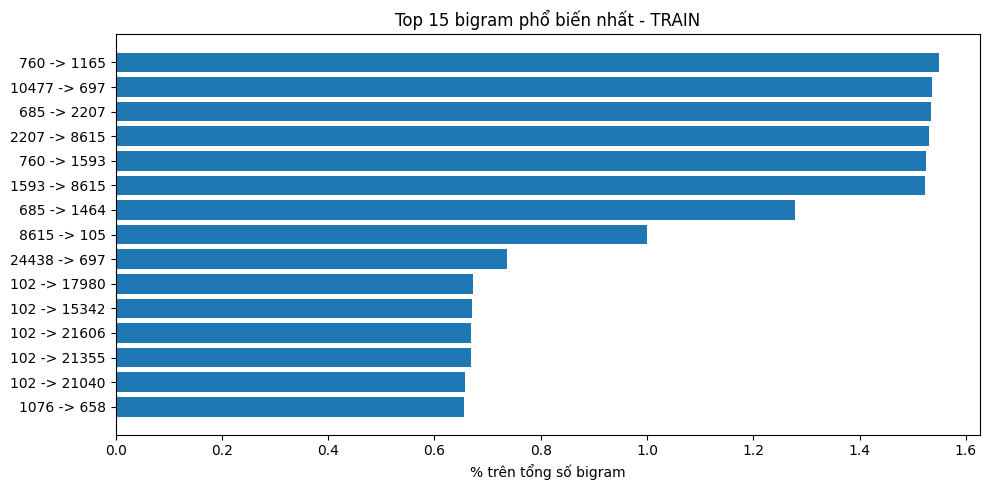

,prev,next,count,share,p_next_given_prev
0,760,1165,9331,1.55%,50.39%
1,10477,697,9256,1.54%,100.00%
2,685,2207,9241,1.53%,54.55%
3,2207,8615,9223,1.53%,100.00%
4,760,1593,9188,1.53%,49.61%
5,1593,8615,9173,1.52%,100.00%
6,685,1464,7700,1.28%,45.45%
7,8615,105,6026,1.00%,32.81%
8,24438,697,4442,0.74%,67.05%
9,102,17980,4056,0.67%,9.92%



===== BIGRAM ANALYSIS - VALID =====
Tổng số bigram: 108,107
Số bigram khác nhau: 3,890
Top 10 bigram bao phủ: 12.24%
Top 100 bigram bao phủ: 52.73%
Tỷ lệ bigram chỉ xuất hiện 1 lần: 32.08%
Tỷ lệ bigram xuất hiện <= 5 lần: 60.46%


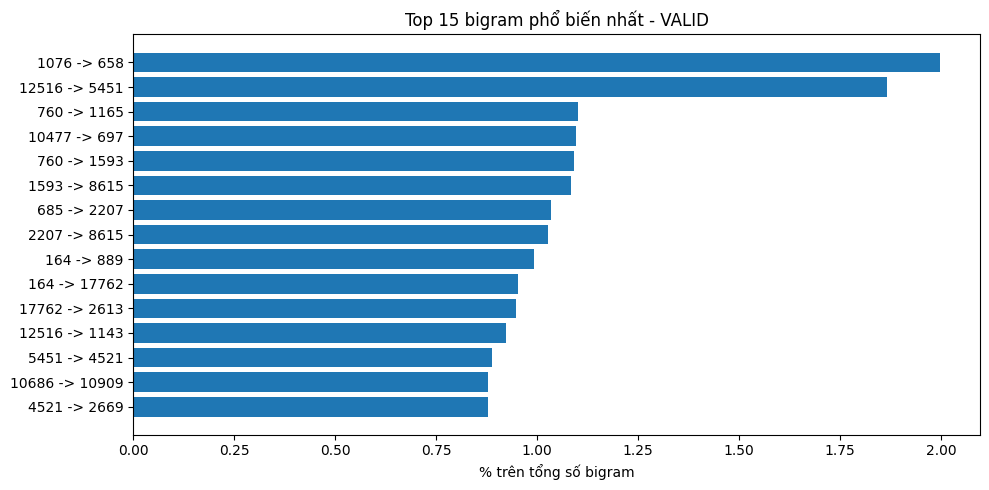

,prev,next,count,share,p_next_given_prev
0,1076,658,2158,2.00%,100.00%
1,12516,5451,2016,1.86%,66.89%
2,760,1165,1191,1.10%,50.27%
3,10477,697,1184,1.10%,100.00%
4,760,1593,1178,1.09%,49.73%
5,1593,8615,1170,1.08%,100.00%
6,685,2207,1119,1.04%,86.08%
7,2207,8615,1110,1.03%,100.00%
8,164,889,1073,0.99%,49.31%
9,164,17762,1030,0.95%,47.33%



===== TRANSITION STRUCTURE - TRAIN =====
Số cạnh gần như cố định (P(next|prev)=100%, support>=50): 38

Top cạnh gần như cố định:


,prev,next,count,share,p_next_given_prev
0,10477,697,9256,1.54%,100.00%
1,2207,8615,9223,1.53%,100.00%
2,1593,8615,9173,1.52%,100.00%
3,1076,658,3953,0.66%,100.00%
4,2621,166,2246,0.37%,100.00%
5,7362,2621,2246,0.37%,100.00%
6,161,824,2183,0.36%,100.00%
7,20645,161,2183,0.36%,100.00%
8,10686,10909,1657,0.28%,100.00%
9,17762,2613,1652,0.27%,100.00%



Top event có nhiều nhánh đi tiếp nhất:


,prev,out_degree,total_from_prev,top1_next_share
0,103,156,25640,14.22%
1,105,135,56478,4.79%
2,102,135,40885,9.92%
3,929,123,10146,37.42%
4,867,119,10445,36.24%
5,775,113,2604,36.29%
6,4425,109,1521,30.90%
7,1243,108,2520,39.37%
8,905,107,2495,39.08%
9,976,107,2491,36.97%


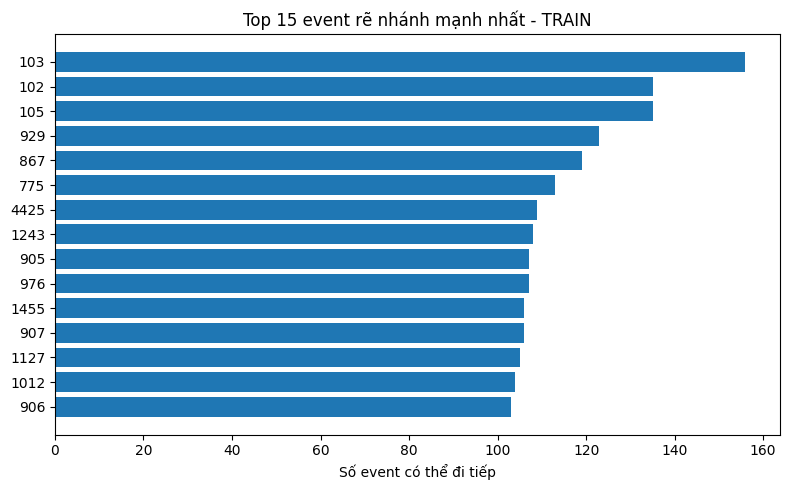


===== TRANSITION STRUCTURE - VALID =====
Số cạnh gần như cố định (P(next|prev)=100%, support>=20): 40

Top cạnh gần như cố định:


,prev,next,count,share,p_next_given_prev
0,1076,658,2158,2.00%,100.00%
1,10477,697,1184,1.10%,100.00%
2,1593,8615,1170,1.08%,100.00%
3,2207,8615,1110,1.03%,100.00%
4,17762,2613,1023,0.95%,100.00%
5,4521,2669,949,0.88%,100.00%
6,10686,10909,949,0.88%,100.00%
7,10909,704,944,0.87%,100.00%
8,131,709,566,0.52%,100.00%
9,1990,621,566,0.52%,100.00%



Top event có nhiều nhánh đi tiếp nhất:


,prev,out_degree,total_from_prev,top1_next_share
0,105,135,5784,5.34%
1,102,131,7638,9.86%
2,103,108,5091,8.52%
3,867,78,689,21.63%
4,697,70,1329,29.27%
5,929,70,538,23.05%
6,8615,69,2269,30.15%
7,7943,67,1221,33.82%
8,1143,67,1026,35.67%
9,704,67,938,30.60%


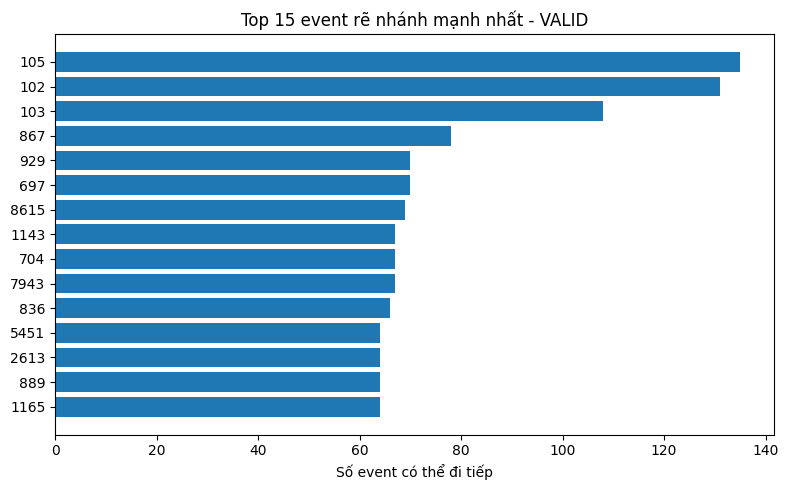


===== PREFIX-3 FLOW - TRAIN =====
Số prefix-3 khác nhau: 4,859
Top 10 prefix-3 bao phủ: 33.31%


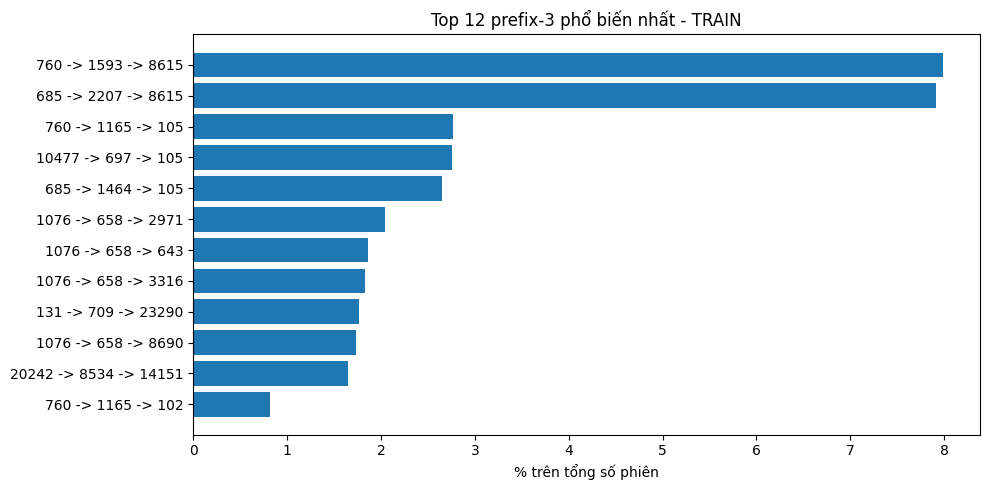

,prefix_str,count,share
0,760 -> 1593 -> 8615,4071,7.98%
1,685 -> 2207 -> 8615,4033,7.91%
2,760 -> 1165 -> 105,1414,2.77%
3,10477 -> 697 -> 105,1406,2.76%
4,685 -> 1464 -> 105,1352,2.65%
5,1076 -> 658 -> 2971,1041,2.04%
6,1076 -> 658 -> 643,951,1.86%
7,1076 -> 658 -> 3316,934,1.83%
8,131 -> 709 -> 23290,903,1.77%
9,1076 -> 658 -> 8690,885,1.74%



===== PREFIX-3 FLOW - VALID =====
Số prefix-3 khác nhau: 831
Top 10 prefix-3 bao phủ: 58.19%


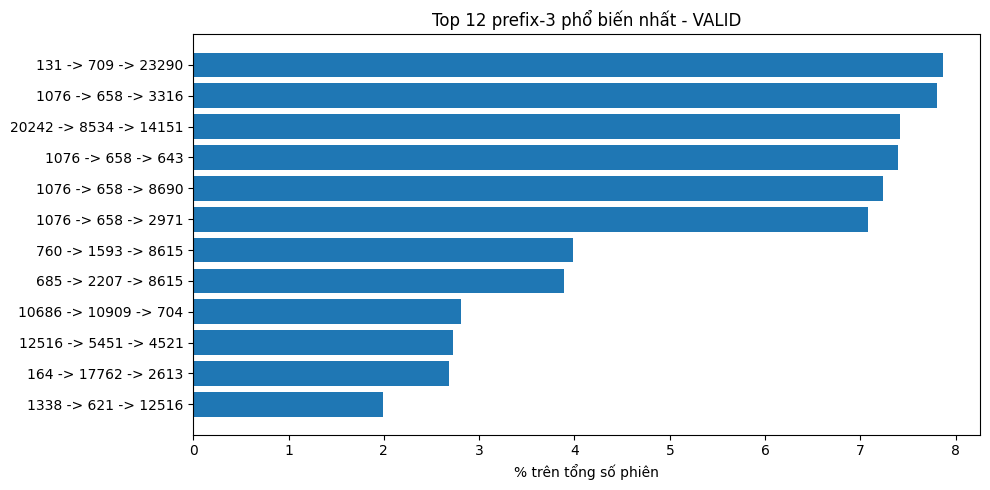

,prefix_str,count,share
0,131 -> 709 -> 23290,566,7.86%
1,1076 -> 658 -> 3316,562,7.81%
2,20242 -> 8534 -> 14151,534,7.42%
3,1076 -> 658 -> 643,532,7.39%
4,1076 -> 658 -> 8690,521,7.24%
5,1076 -> 658 -> 2971,510,7.08%
6,760 -> 1593 -> 8615,287,3.99%
7,685 -> 2207 -> 8615,280,3.89%
8,10686 -> 10909 -> 704,202,2.81%
9,12516 -> 5451 -> 4521,196,2.72%



===== BIGRAM DRIFT: TRAIN vs VALID =====


,pair,share_train,share_val,abs_diff
0,1076 -> 658,0.66%,2.00%,1.34%
1,12516 -> 5451,0.55%,1.86%,1.32%
2,685 -> 1464,1.28%,0.17%,1.11%
3,164 -> 889,0.27%,0.99%,0.72%
4,164 -> 17762,0.28%,0.95%,0.68%
5,17762 -> 2613,0.27%,0.95%,0.67%
6,12516 -> 1143,0.27%,0.92%,0.65%
7,24438 -> 697,0.74%,0.11%,0.63%
8,5451 -> 4521,0.27%,0.89%,0.62%
9,4521 -> 2669,0.26%,0.88%,0.61%


In [38]:
bg_train = analyze_bigrams(X_train, feat_cols, "TRAIN", top_n=15)
bg_val = analyze_bigrams(X_val, feat_cols, "VALID", top_n=15)

det_train, branch_train = analyze_transition_structure(bg_train, "TRAIN", min_support=50, top_n=15)
det_val, branch_val = analyze_transition_structure(bg_val, "VALID", min_support=20, top_n=15)

prefix3_train = analyze_prefix_flow(X_train, feat_cols, "TRAIN", k=3, top_n=12)
prefix3_val = analyze_prefix_flow(X_val, feat_cols, "VALID", k=3, top_n=12)

bigram_drift = compare_bigram_drift(bg_train, bg_val, top_n=15)

Nhận xét
- Top 10 bigram bao phủ 12,89% (khá cao) nhưng chưa đủ áp đảo 
- Bigram đa dạng, có nhiều bigram hiếm --> hành vi phân mảnh mạnh 
- 38 hành vi luôn đi cùng nhau với tỉ lệ khá lớn 
- Tuy nhiên, nó lại lệch khá nhiều ở tập VALID so với TRAIN 

==> Cần model sequence học ngữ cảnh dài, thay vì chỉ dựa vào các nhóm prefix, bigram nông 


## Mối quan hệ với nhãn 

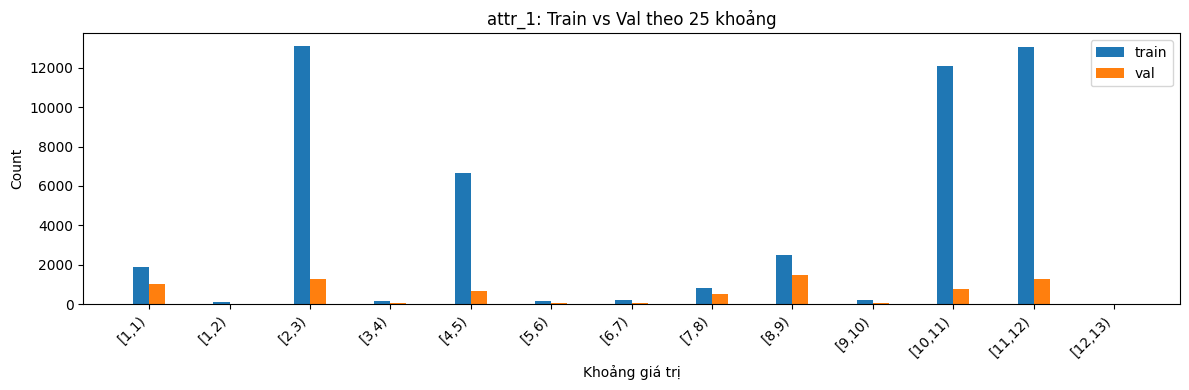

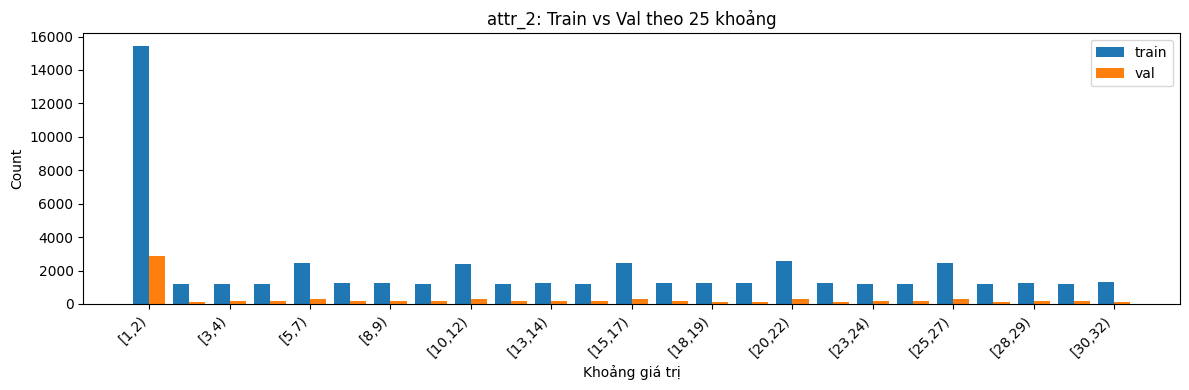

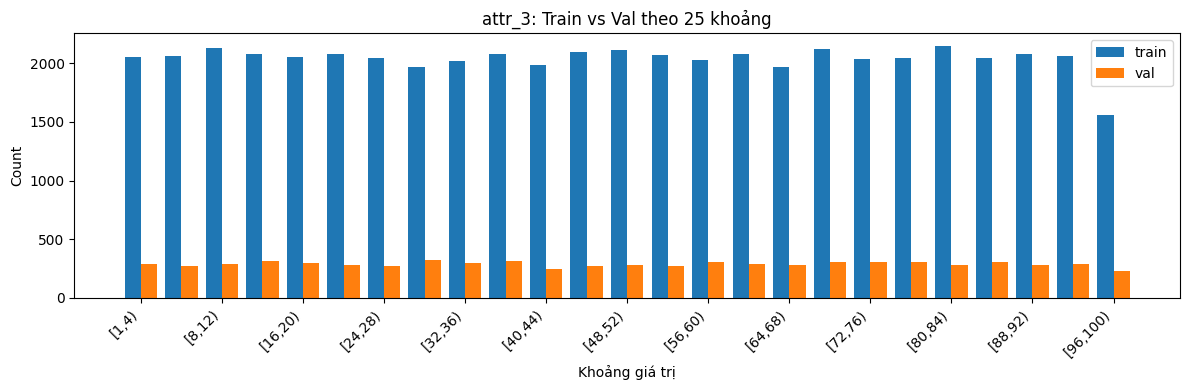

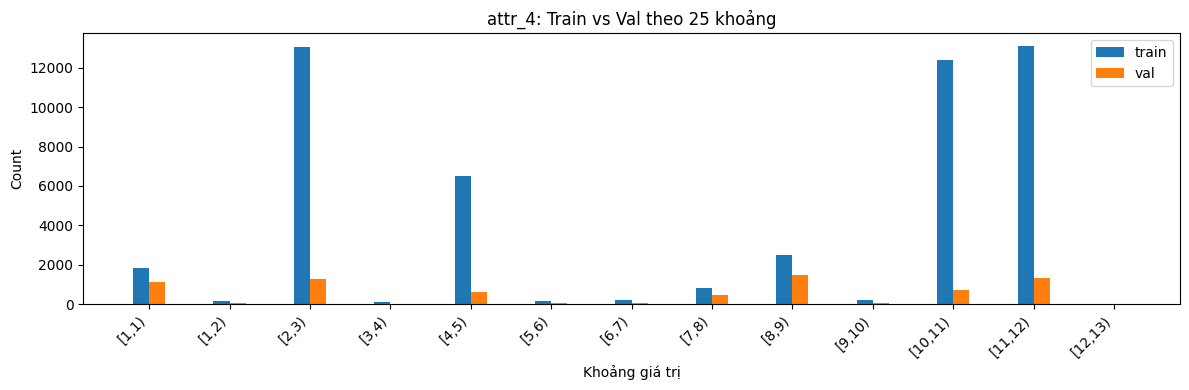

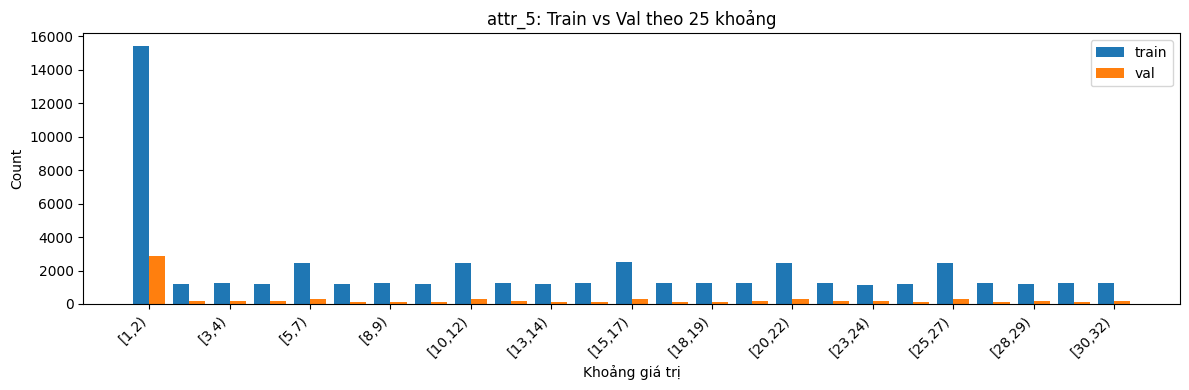

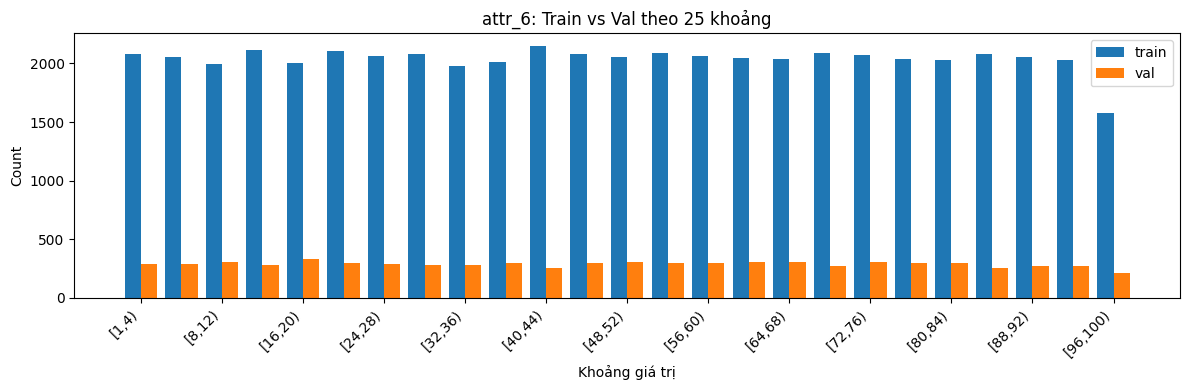

In [39]:
attrs = [c for c in y_train.columns if c.startswith("attr_")]

N_BINS = 25                 # số khoảng (bins) cố định cho mọi attr
FIGSIZE = (12, 4)           # mọi biểu đồ cùng kích thước
SHOW_PERCENT = False        # True nếu muốn so theo % thay vì count

for a in attrs:
    # 1) Lấy toàn bộ giá trị của attr ở train+val (giả định là số nguyên)
    all_vals = pd.concat([y_train[a], y_val[a]], ignore_index=True)

    vmin, vmax = int(all_vals.min()), int(all_vals.max())

    # 2) Tạo bins đều nhau theo khoảng [vmin, vmax]
    # +1 để bao phủ vmax khi dùng bins kiểu số nguyên
    edges = np.linspace(vmin, vmax + 1, N_BINS + 1)

    # 3) Đếm số lượng theo bin
    tr_bin = pd.cut(y_train[a], bins=edges, right=False, include_lowest=True).value_counts().sort_index()
    va_bin = pd.cut(y_val[a],   bins=edges, right=False, include_lowest=True).value_counts().sort_index()

    # 4) Nếu muốn so công bằng (train/val size khác nhau) thì chuyển sang %
    if SHOW_PERCENT:
        tr_y = tr_bin.values / tr_bin.values.sum() * 100
        va_y = va_bin.values / va_bin.values.sum() * 100
        ylabel = "Tỷ lệ (%)"
    else:
        tr_y = tr_bin.values
        va_y = va_bin.values
        ylabel = "Count"

    # 5) Vẽ 2 cột cạnh nhau
    labels = [f"[{int(iv.left)},{int(iv.right)})" for iv in tr_bin.index]  # nhãn dạng khoảng
    x = np.arange(len(labels))
    w = 0.4

    plt.figure(figsize=FIGSIZE)
    plt.bar(x - w/2, tr_y, width=w, label="train")
    plt.bar(x + w/2, va_y, width=w, label="val")

    plt.title(f"{a}: Train vs Val theo {N_BINS} khoảng")
    plt.xlabel("Khoảng giá trị")
    plt.ylabel(ylabel)

    # Giảm rối nhãn trục x nếu nhiều bins
    step = max(1, len(labels)//12)           # chỉ hiện ~12 nhãn
    plt.xticks(x[::step], labels[::step], rotation=45, ha="right")

    plt.legend()
    plt.tight_layout()
    plt.show()

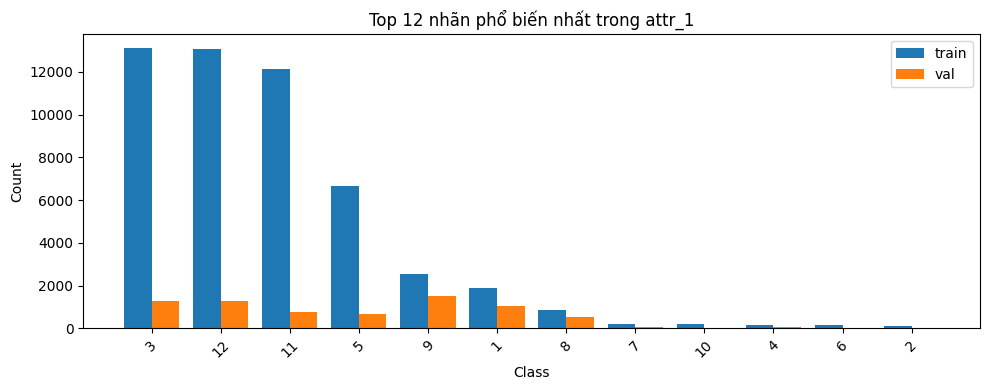

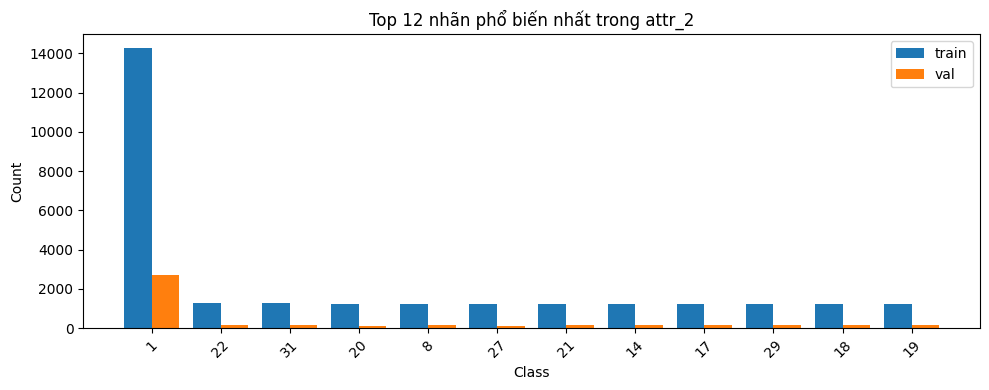

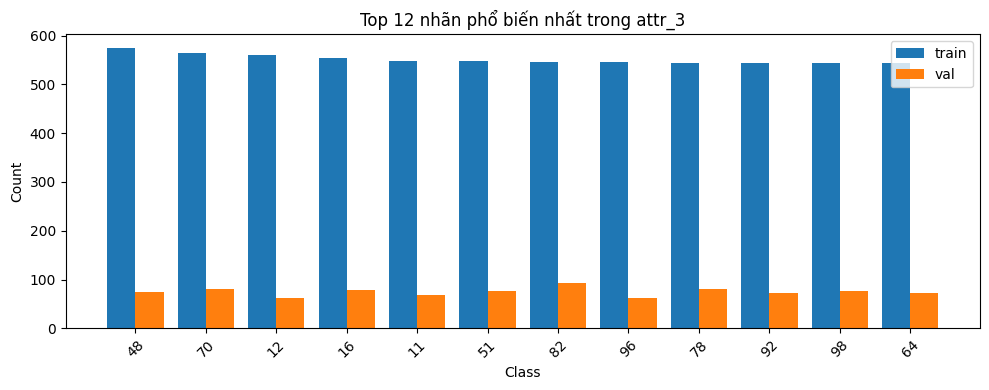

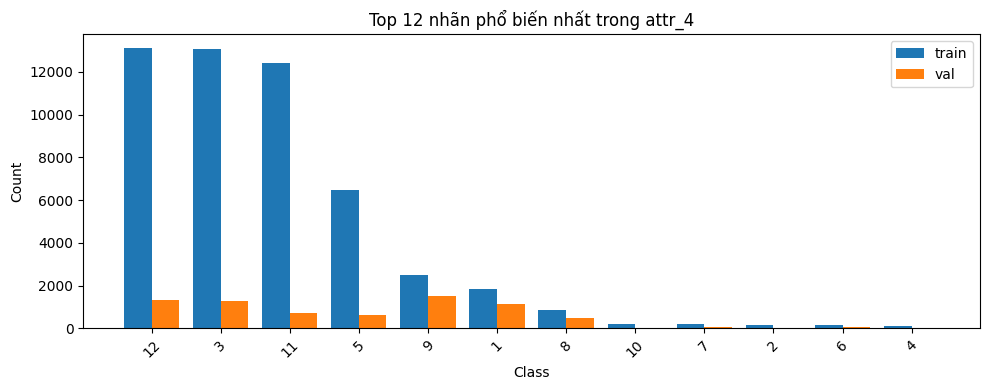

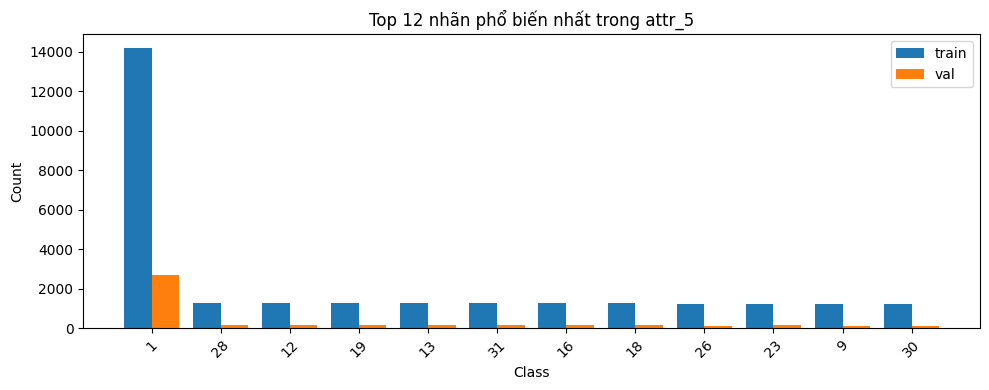

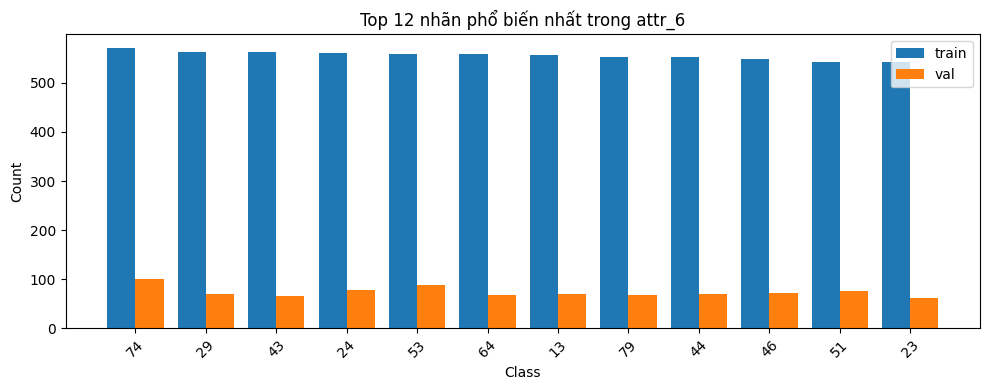

In [40]:
import numpy as np
import matplotlib.pyplot as plt

attrs = [c for c in y_train.columns if c.startswith("attr_")]
top_k = 12  # số lớp hiển thị (top-k lớp phổ biến nhất trong train)

for a in attrs:
    # Lấy top-k lớp phổ biến trong train
    tr_counts = y_train[a].value_counts().head(top_k)

    # Lấy count của val theo đúng thứ tự lớp của train (lớp không có thì =0)
    va_counts = y_val[a].value_counts().reindex(tr_counts.index, fill_value=0)

    x = np.arange(len(tr_counts))
    w = 0.4  # độ rộng mỗi cột

    plt.figure(figsize=(10, 4))
    plt.bar(x - w/2, tr_counts.values, width=w, label="train")
    plt.bar(x + w/2, va_counts.values, width=w, label="val")

    plt.title(f"Top {top_k} nhãn phổ biến nhất trong {a}")
    plt.xticks(x, tr_counts.index.astype(str), rotation=45)
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [41]:
target_cols = [c for c in y_train.columns if c.startswith("attr")]
print("Target columns:", target_cols)


# Nếu chưa có build_sequences thì định nghĩa lại
def build_sequences(X, cols):
    arr = X[cols].to_numpy()
    seqs = []
    for row in arr:
        seq = row[~pd.isna(row)].astype(int).tolist()
        seqs.append(seq)
    return seqs


# Event presence theo vocab train
def build_event_presence_from_vocab(X, cols, vocab_events):
    seqs = build_sequences(X, cols)
    rows = []

    for seq in seqs:
        s = set(seq)
        rows.append({f"event_{e}": int(e in s) for e in vocab_events})

    return pd.DataFrame(rows)


# Bigram presence theo vocab train
def build_bigram_presence_from_vocab(X, cols, vocab_bigrams):
    seqs = build_sequences(X, cols)
    rows = []

    for seq in seqs:
        bg_set = set(zip(seq[:-1], seq[1:]))
        rows.append({f"bg_{a}_{b}": int((a, b) in bg_set) for a, b in vocab_bigrams})

    return pd.DataFrame(rows)


# Lấy vocab event từ train
seqs_train = build_sequences(X_train, feat_cols)

event_counter = Counter()
bigram_counter = Counter()

for seq in seqs_train:
    event_counter.update(set(seq))                  # presence theo phiên
    bigram_counter.update(set(zip(seq[:-1], seq[1:])))  # presence theo phiên

# Có thể chỉnh top_k nếu muốn chạy nhanh hơn / mạnh hơn
top_k_events = 250
top_k_bigrams = 300

top_events = [e for e, _ in event_counter.most_common(top_k_events)]
top_bigrams = [bg for bg, _ in bigram_counter.most_common(top_k_bigrams)]

event_presence_train = build_event_presence_from_vocab(X_train, feat_cols, top_events)
event_presence_val = build_event_presence_from_vocab(X_val, feat_cols, top_events)

bigram_presence_train = build_bigram_presence_from_vocab(X_train, feat_cols, top_bigrams)
bigram_presence_val = build_bigram_presence_from_vocab(X_val, feat_cols, top_bigrams)

print("Event presence train:", event_presence_train.shape)
print("Event presence val  :", event_presence_val.shape)
print("Bigram presence train:", bigram_presence_train.shape)
print("Bigram presence val  :", bigram_presence_val.shape)

Target columns: ['attr_1', 'attr_2', 'attr_3', 'attr_4', 'attr_5', 'attr_6']
Event presence train: (51000, 250)
Event presence val  : (7200, 250)
Bigram presence train: (51000, 300)
Bigram presence val  : (7200, 300)


In [42]:
rollback + token lặp lại 

SyntaxError: invalid syntax (3509617227.py, line 1)

# Tổng hợp

In [ ]:
def row_to_seq(row, cols):
    # Lấy các action-id (bỏ NaN padding) -> list int
    vals = row[cols].dropna().astype(int).tolist()
    return vals

def entropy(seq):
    # Entropy đo độ đa dạng hành động (cao = nhiều loại hành động, phân bố đều)
    if len(seq) == 0: 
        return 0.0
    cnt = Counter(seq)
    p = np.array(list(cnt.values()), dtype=float) / len(seq)
    return float(-(p * np.log(p + 1e-12)).sum())

def rollback_aba(seq):
    # Đếm pattern A->B->A (proxy cho back-and-forth/rollback)
    if len(seq) < 3: 
        return 0
    s = 0
    for i in range(len(seq)-2):
        if seq[i] == seq[i+2] and seq[i] != seq[i+1]:
            s += 1
    return s

def build_stats(X, cols):
    rows = []
    for _, r in X.iterrows():
        s = row_to_seq(r, cols)
        L = len(s)
        U = len(set(s))
        rep = 0 if L == 0 else 1 - U/L     # tỷ lệ lặp: càng cao càng lặp nhiều
        ent = entropy(s)
        rb  = rollback_aba(s)
        rows.append((L, U, rep, ent, rb))
    return pd.DataFrame(rows, columns=["seq_len", "unique_actions", "repeat_ratio", "entropy", "rollback_aba"])

tr_stat = build_stats(X_train, feat_cols)
va_stat = build_stats(X_val, feat_cols)

tr_stat.describe().T

,count,mean,std,min,25%,50%,75%,max
seq_len,51000.0,12.811333,4.601317,3.000000,9.000000,12.000000,15.000000,37.000000
unique_actions,51000.0,10.911451,3.404443,2.000000,9.000000,10.000000,13.000000,26.000000
repeat_ratio,51000.0,0.135807,0.103635,0.000000,0.066667,0.111111,0.222222,0.615385
entropy,51000.0,2.290485,0.297865,0.636514,2.043192,2.242973,2.512659,3.170493
rollback_aba,51000.0,0.394471,0.805553,0.000000,0.000000,0.000000,0.000000,4.000000


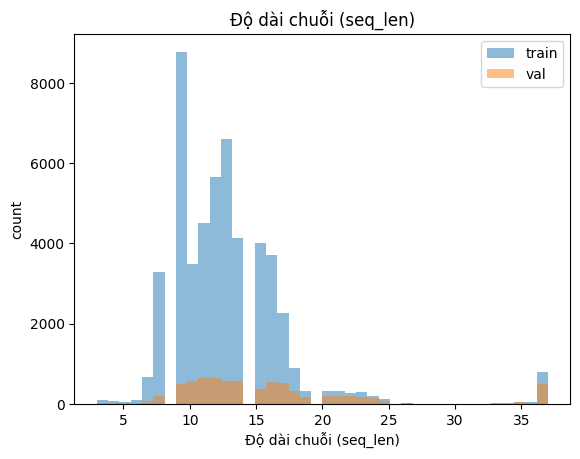

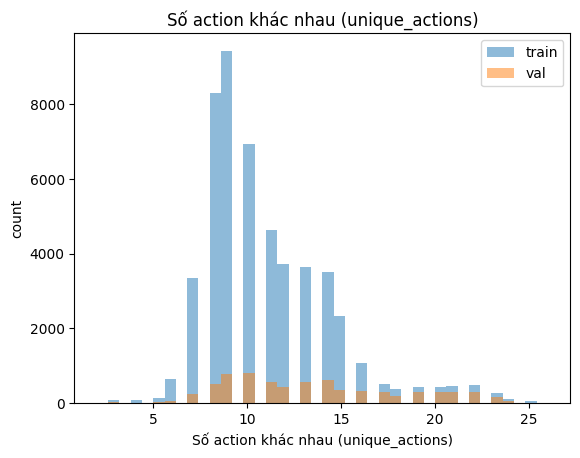

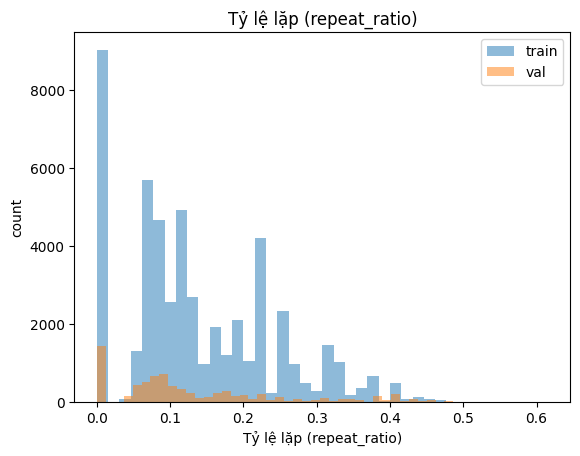

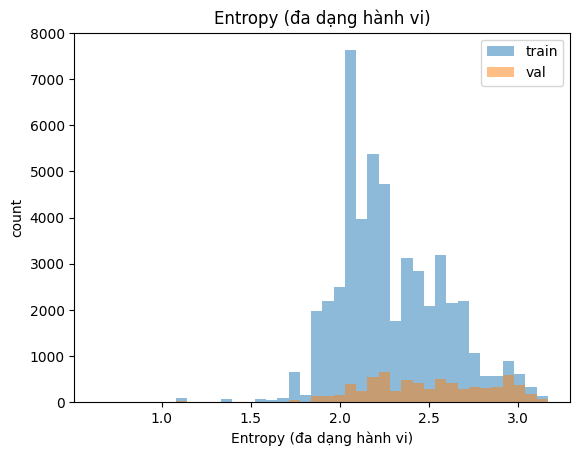

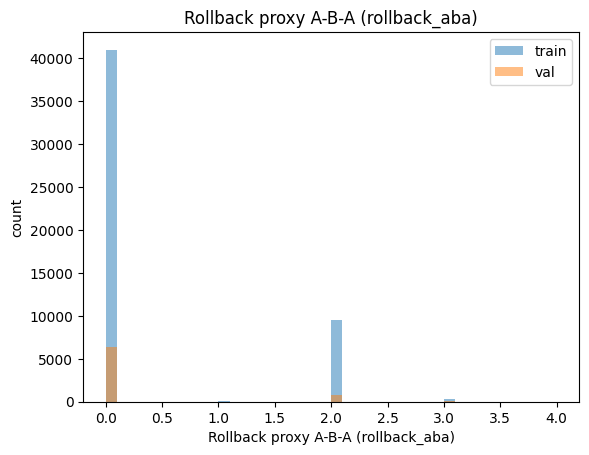

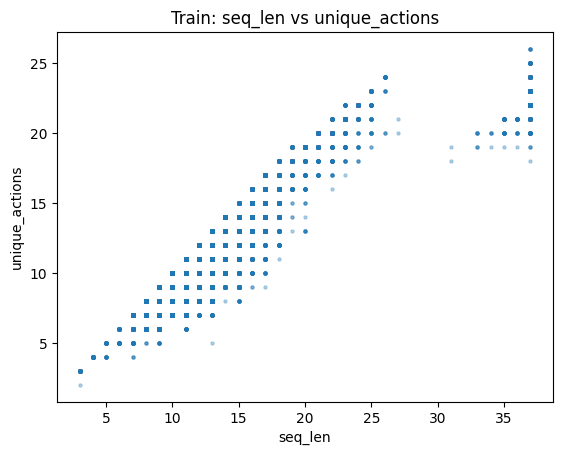

In [ ]:
def hist2(a, b, title, bins=40):
    plt.figure()
    plt.hist(a, bins=bins, alpha=0.5, label="train")
    plt.hist(b, bins=bins, alpha=0.5, label="val")
    plt.title(title)
    plt.xlabel(title)
    plt.ylabel("count")
    plt.legend()
    plt.show()

hist2(tr_stat["seq_len"], va_stat["seq_len"], "Độ dài chuỗi (seq_len)")
hist2(tr_stat["unique_actions"], va_stat["unique_actions"], "Số action khác nhau (unique_actions)")
hist2(tr_stat["repeat_ratio"], va_stat["repeat_ratio"], "Tỷ lệ lặp (repeat_ratio)")
hist2(tr_stat["entropy"], va_stat["entropy"], "Entropy (đa dạng hành vi)")
hist2(tr_stat["rollback_aba"], va_stat["rollback_aba"], "Rollback proxy A-B-A (rollback_aba)")

# Scatter để nhìn cấu trúc nhóm hành vi
plt.figure()
plt.scatter(tr_stat["seq_len"], tr_stat["unique_actions"], s=5, alpha=0.3)
plt.title("Train: seq_len vs unique_actions")
plt.xlabel("seq_len"); plt.ylabel("unique_actions")
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


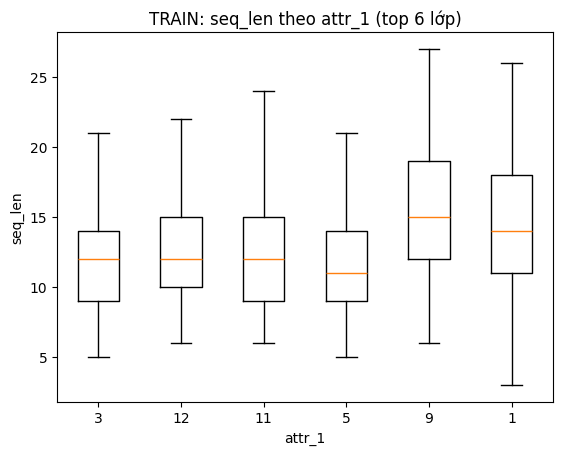

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


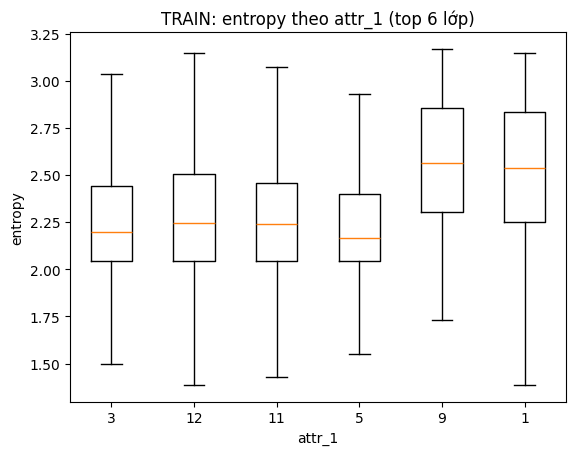

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


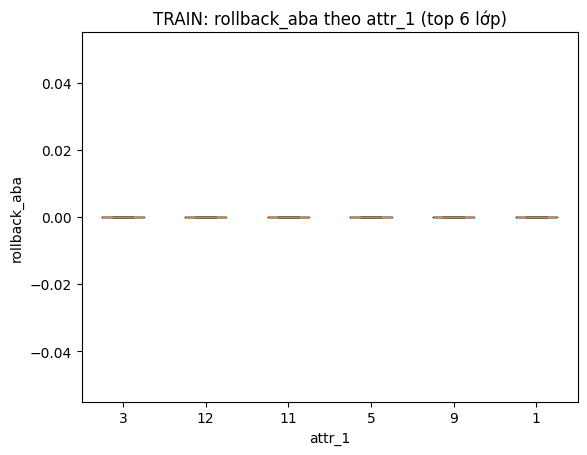

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


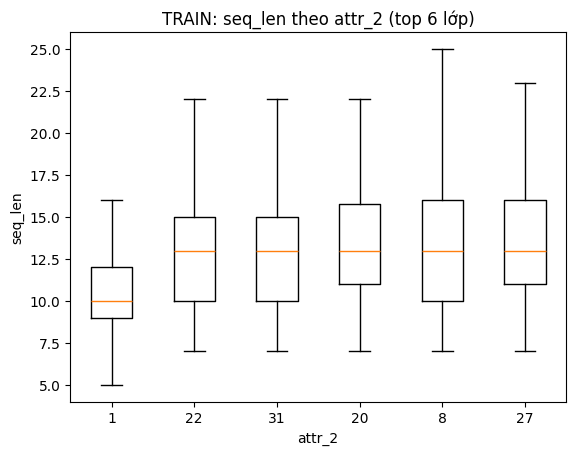

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


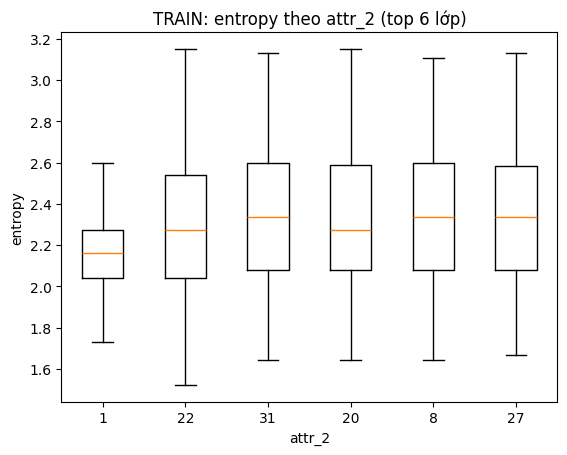

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


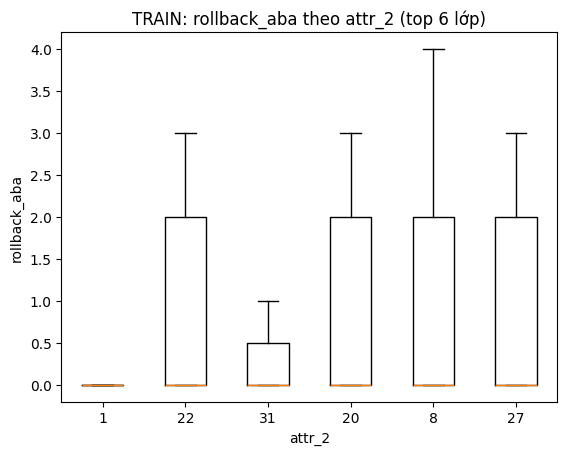

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


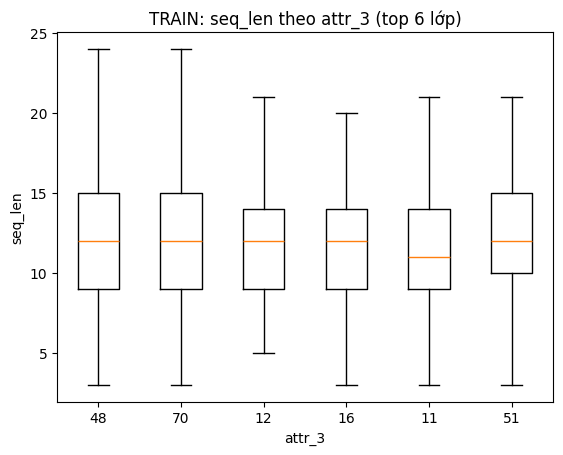

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


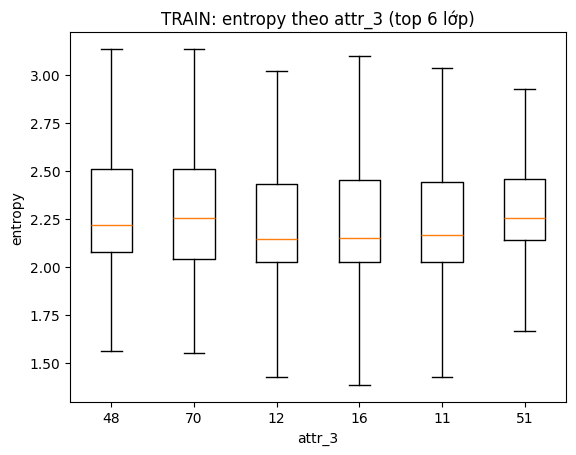

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


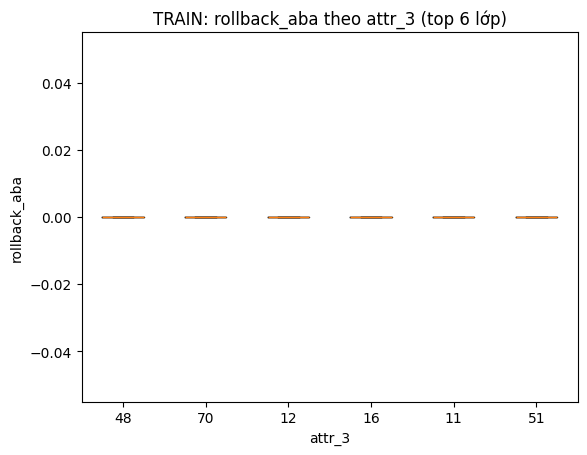

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


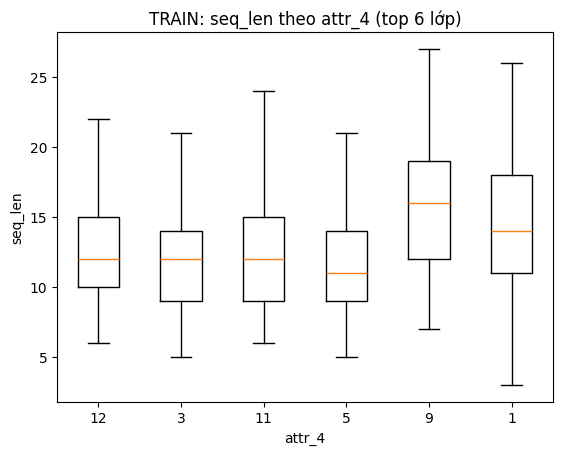

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


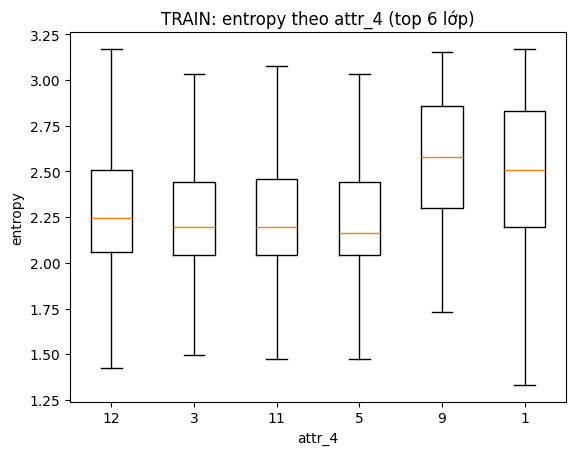

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


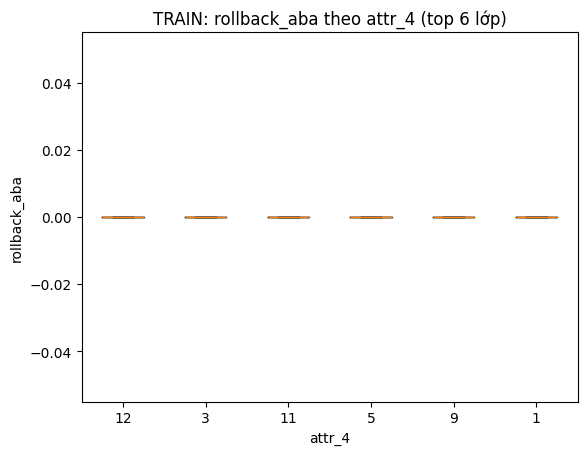

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


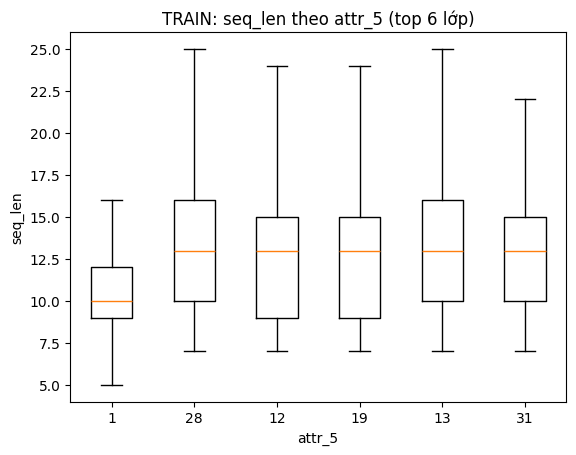

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


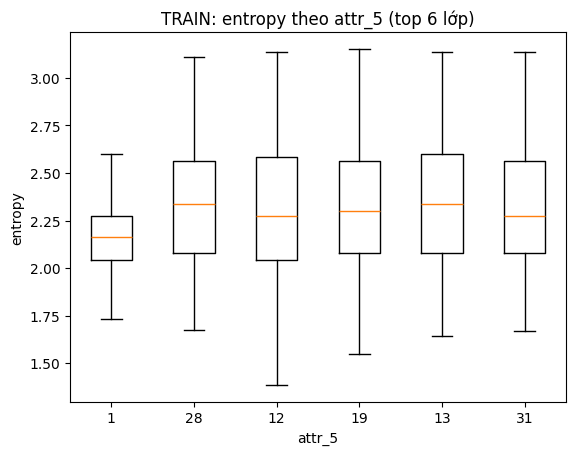

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


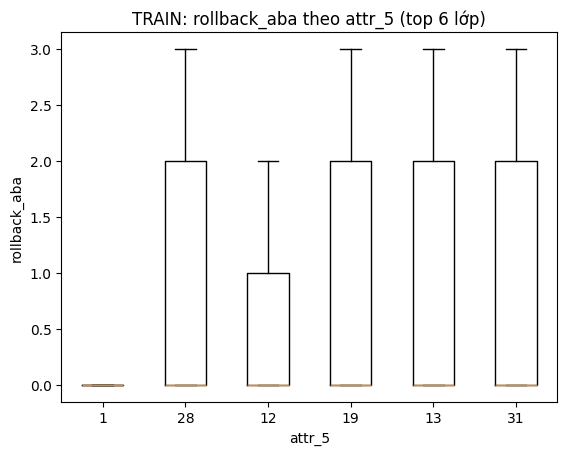

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


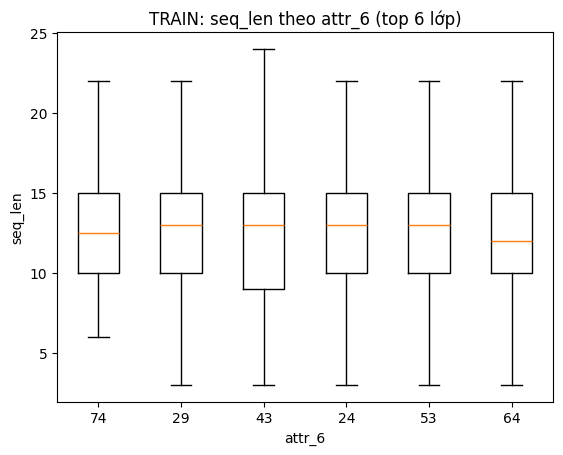

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


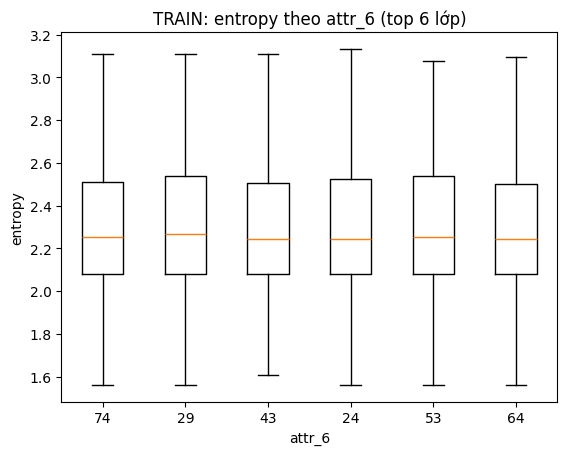

C:\Users\Admin\AppData\Local\Temp\ipykernel_25172\2692057622.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)


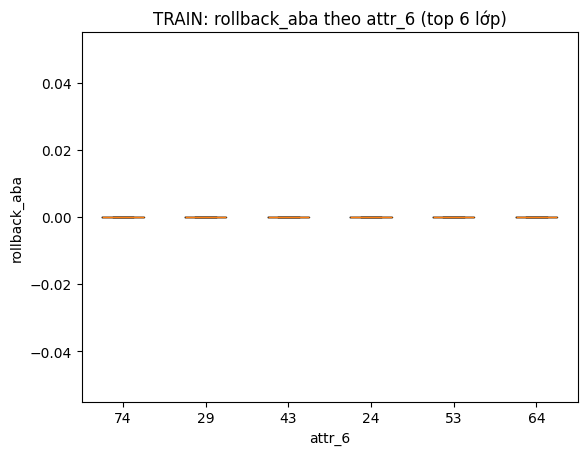

In [ ]:
# Gộp stats vào Y theo id (train)
tr_feat = pd.concat([X_train[["id"]].reset_index(drop=True), tr_stat.reset_index(drop=True)], axis=1)
va_feat = pd.concat([X_val[["id"]].reset_index(drop=True), va_stat.reset_index(drop=True)], axis=1)

tr_all = tr_feat.merge(y_train, on="id")
va_all = va_feat.merge(y_val, on="id")

def box_by_attr(df, attr, col, top_n=6):
    # So sánh col theo top_n lớp phổ biến của attr
    top_cls = df[attr].value_counts().head(top_n).index.tolist()
    data = [df[df[attr]==c][col].values for c in top_cls]

    plt.figure()
    plt.boxplot(data, labels=[str(c) for c in top_cls], showfliers=False)
    plt.title(f"TRAIN: {col} theo {attr} (top {top_n} lớp)")
    plt.xlabel(attr); plt.ylabel(col)
    plt.show()

for a in attrs:
    box_by_attr(tr_all, a, "seq_len", top_n=6)
    box_by_attr(tr_all, a, "entropy", top_n=6)
    box_by_attr(tr_all, a, "rollback_aba", top_n=6)

In [ ]:
import pandas as pd
import numpy as np
from collections import Counter
from IPython.display import display
import matplotlib.pyplot as plt

# Chuẩn hoá target
if "y_train" in globals():
    YTR = y_train.copy()
else:
    YTR = Y_train.copy()

if "y_val" in globals():
    YVA = y_val.copy()
else:
    YVA = Y_val.copy()

target_cols = [c for c in YTR.columns if c.startswith("attr")]
print("Target columns:", target_cols)


def build_sequences(X, cols):
    arr = X[cols].to_numpy()
    seqs = []
    for row in arr:
        seq = row[~pd.isna(row)].astype(int).tolist()
        seqs.append(seq)
    return seqs


# Presence theo vocab train
def build_event_presence_from_vocab(X, cols, vocab_events):
    seqs = build_sequences(X, cols)
    rows = []

    for seq in seqs:
        s = set(seq)
        rows.append({f"event_{e}": int(e in s) for e in vocab_events})

    return pd.DataFrame(rows)


def build_bigram_presence_from_vocab(X, cols, vocab_bigrams):
    seqs = build_sequences(X, cols)
    rows = []

    for seq in seqs:
        bg_set = set(zip(seq[:-1], seq[1:]))
        rows.append({f"bg_{a}_{b}": int((a, b) in bg_set) for a, b in vocab_bigrams})

    return pd.DataFrame(rows)


# Lấy vocab train
seqs_train = build_sequences(X_train, feat_cols)

event_counter = Counter()
bigram_counter = Counter()

for seq in seqs_train:
    event_counter.update(set(seq))                  # presence theo chuỗi
    bigram_counter.update(set(zip(seq[:-1], seq[1:])))

# Bạn có thể tăng/giảm cho nhanh/chậm
top_k_events = 250
top_k_bigrams = 300

top_events = [e for e, _ in event_counter.most_common(top_k_events)]
top_bigrams = [bg for bg, _ in bigram_counter.most_common(top_k_bigrams)]

event_presence_train = build_event_presence_from_vocab(X_train, feat_cols, top_events)
event_presence_val = build_event_presence_from_vocab(X_val, feat_cols, top_events)

bigram_presence_train = build_bigram_presence_from_vocab(X_train, feat_cols, top_bigrams)
bigram_presence_val = build_bigram_presence_from_vocab(X_val, feat_cols, top_bigrams)

# Kết hợp
event_bigram_train = pd.concat([event_presence_train, bigram_presence_train], axis=1)
event_bigram_val = pd.concat([event_presence_val, bigram_presence_val], axis=1)

print("Event train :", event_presence_train.shape)
print("Bigram train:", bigram_presence_train.shape)
print("Event+Bigram train:", event_bigram_train.shape)

Target columns: ['attr_1', 'attr_2', 'attr_3', 'attr_4', 'attr_5', 'attr_6']
Event train : (51000, 250)
Bigram train: (51000, 300)
Event+Bigram train: (51000, 550)


In [ ]:
from sklearn.feature_selection import mutual_info_classif

def mutual_info_summary(X_bin, y, feature_type, attr_name, top_n=20):
    mi = mutual_info_classif(X_bin, y, discrete_features=True, random_state=42)
    mi_df = pd.DataFrame({
        "feature": X_bin.columns,
        "mi": mi
    }).sort_values("mi", ascending=False).reset_index(drop=True)

    summary = {
        "attr": attr_name,
        "feature_type": feature_type,
        "avg_top_mi": mi_df["mi"].head(top_n).mean(),
        "sum_top_mi": mi_df["mi"].head(top_n).sum(),
        "max_mi": mi_df["mi"].max(),
        "n_feature_mi_gt_0": int((mi_df["mi"] > 0).sum())
    }
    return pd.DataFrame([summary]), mi_df


mi_summary_rows = []
mi_detail = {}

for col in target_cols:
    s_e, d_e = mutual_info_summary(event_presence_train, y_train[col], "event", col, top_n=20)
    s_b, d_b = mutual_info_summary(bigram_presence_train, y_train[col], "bigram", col, top_n=20)
    s_eb, d_eb = mutual_info_summary(event_bigram_train, y_train[col], "event+bigram", col, top_n=20)

    mi_summary_rows.extend([s_e, s_b, s_eb])
    mi_detail[(col, "event")] = d_e
    mi_detail[(col, "bigram")] = d_b
    mi_detail[(col, "event+bigram")] = d_eb

mi_summary = pd.concat(mi_summary_rows, axis=0).reset_index(drop=True)

print("===== SO SÁNH MUTUAL INFORMATION =====")
display(
    mi_summary.sort_values(["attr", "feature_type"])
    .style.format({
        "avg_top_mi": "{:.4f}",
        "sum_top_mi": "{:.4f}",
        "max_mi": "{:.4f}"
    })
)

===== SO SÁNH MUTUAL INFORMATION =====


,attr,feature_type,avg_top_mi,sum_top_mi,max_mi,n_feature_mi_gt_0
1,attr_1,bigram,0.0504,1.0085,0.0861,300
0,attr_1,event,0.0725,1.4500,0.1308,250
2,attr_1,event+bigram,0.0775,1.5505,0.1308,550
4,attr_2,bigram,0.0236,0.4728,0.0246,300
3,attr_2,event,0.0849,1.6984,0.0892,250
5,attr_2,event+bigram,0.0849,1.6984,0.0892,550
7,attr_3,bigram,0.0611,1.2227,0.0834,300
6,attr_3,event,0.1250,2.4994,0.1478,250
8,attr_3,event+bigram,0.1295,2.5894,0.1478,550
10,attr_4,bigram,0.0620,1.2393,0.1057,300
